
# RAP 10 m at fixed field locations: temporal distributions and monitored-year comparison

## Questions

This notebook evaluates two related questions:

1. **How stable are RAP 10 m cover estimates through time at the same fixed field locations?**
   - annual cover distributions
   - within-location trajectories
   - annual changes
   - rank stability / temporal consistency among plots

2. **How closely do RAP 10 m estimates agree with field-measured cover in the year a plot was monitored?**
   - paired monitored-year comparisons
   - bias, MAE, RMSE, correlation
   - diagnostic plots

### Important interpretation

Temporal stability is **not the same thing as accuracy**. If RAP has spatially structured errors on the Snake River Plain, a persistent bias could still generate highly stable trajectories. This notebook therefore separates:

- **temporal consistency** of RAP at fixed locations, from
- **agreement with field measurements** where we actually have monitored-year observations.

Also, RAP AFG/PFG and the field functional groups are not necessarily biologically homologous. Those comparisons should only be enabled if the mapping is defensible. Sagebrush, shrub, bare ground, litter, and tree diagnostics may have cleaner interpretations depending on the field schema.


In [1]:

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore", category=FutureWarning)



## 1. Paths and analysis configuration

Use explicit absolute paths. The RAP directory should contain the annual exports:

`NCA_FieldPlots_RAP10_2018.csv` ... `NCA_FieldPlots_RAP10_2025.csv`

If the GEE export already retained the field-cover columns from the master plot table, `FIELD_CSV` can be left as `None`. Otherwise point `FIELD_CSV` to the field table and configure the join key below.


In [2]:

# ---------------------------------------------------------------------------
# EDIT THESE PATHS
# ---------------------------------------------------------------------------

RAP_DIR = Path(r"C:\NCA_DATA\Vegetation Data\RAP")

VEG_PATH = Path(
    r"C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33\Derived"
    r"\NCA_FCM_K5_m1p33_parent_assignments.csv"
)

# Actual columns in the GEE exports.
PLOT_ID = "PlotID"
FIELD_YEAR = "year"
RAP_YEAR = "RAP_Year"

# Canonical monitored-record identifier.
#
# Plot names are reused among monitoring campaigns, so PlotID alone is not
# unique. Every longitudinal operation and vegetation join uses PlotYearID.
RECORD_ID = "PlotYearID"

EXPECTED_YEARS = list(range(2018, 2026))

assert RAP_DIR.is_absolute(), "Use an absolute RAP_DIR path."
assert VEG_PATH.is_absolute(), "Use an absolute VEG_PATH."



### Record identity

`PlotID` is reused among monitoring campaigns and is therefore **not** a unique
record identifier.

Throughout this notebook the canonical key is:

\[
\mathrm{PlotYearID} = \mathrm{field\ monitoring\ year} + \mathrm{PlotID}.
\]

For example, plot `100` sampled in 2016 and plot `100` sampled in 2025 are
different monitored records.

- `PlotYearID` identifies the monitored field record and is used for all joins,
  temporal grouping, differencing, pivots, and validation.
- `year` is the field monitoring year.
- `RAP_Year` is the year represented by the RAP observation.

Each `PlotYearID` is followed through the complete RAP 2018–2025 time series.



## 2. Load and validate annual RAP exports

The central design requirement is that **every annual CSV contains the same fixed plot set**. The checks below test that directly before any analysis.


In [3]:

def extract_year_from_name(path):
    m = re.search(r"(20\d{2})", path.stem)
    return int(m.group(1)) if m else None


files = sorted(RAP_DIR.glob("NCA_FieldPlots_RAP10_*.csv"))

if not files:
    raise FileNotFoundError(
        f"No annual RAP CSVs found in {RAP_DIR}\n"
        "Expected files such as NCA_FieldPlots_RAP10_2018.csv"
    )

frames = []

for path in files:
    year_from_name = extract_year_from_name(path)
    df = pd.read_csv(path)

    # Clean hidden UTF-8 BOM and whitespace from GEE/CSV headers.
    df.columns = (
        df.columns
        .str.replace("\ufeff", "", regex=False)
        .str.strip()
    )

    if RAP_YEAR not in df.columns:
        df[RAP_YEAR] = year_from_name

    frames.append(df)

rap = pd.concat(frames, ignore_index=True)

# Normalize key fields.
rap[RAP_YEAR] = pd.to_numeric(rap[RAP_YEAR], errors="coerce").astype("Int64")
rap[FIELD_YEAR] = pd.to_numeric(rap[FIELD_YEAR], errors="coerce").astype("Int64")
rap[PLOT_ID] = rap[PLOT_ID].astype("string").str.strip()

# Plot labels are reused across monitoring years.
# The unique monitored record is therefore field year × PlotID.
rap[RECORD_ID] = (
    rap[FIELD_YEAR].astype("string")
    + "_"
    + rap[PLOT_ID]
)

print(f"Loaded {len(files)} annual CSVs")
print(f"Rows: {len(rap):,}")
print(f"Columns: {rap.shape[1]}")
print("RAP years:", sorted(rap[RAP_YEAR].dropna().astype(int).unique()))
print("Columns:")
print(rap.columns.tolist())

rap.head()


Loaded 8 annual CSVs
Rows: 7,680
Columns: 14
RAP years: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Columns:
['system:index', 'RAP_AFG', 'RAP_BGR', 'RAP_IAG_IAG', 'RAP_LTR', 'RAP_PFG', 'RAP_SAGE_ARTE', 'RAP_SHR', 'RAP_TRE', 'RAP_Year', 'year', 'PlotID', '.geo', 'PlotYearID']


,system:index,RAP_AFG,RAP_BGR,RAP_IAG_IAG,RAP_LTR,RAP_PFG,RAP_SAGE_ARTE,RAP_SHR,RAP_TRE,RAP_Year,year,PlotID,.geo,PlotYearID
0,00000000000000000000,26,25,17,17,17,1,4,0,2018,2016,100,"{""type"":""Point"",""coordinates"":[-115.8952595330...",2016_100
1,00000000000000000001,35,18,21,18,15,2,5,1,2018,2016,101,"{""type"":""Point"",""coordinates"":[-115.8944921088...",2016_101
2,00000000000000000002,44,19,36,21,8,2,3,0,2018,2016,102,"{""type"":""Point"",""coordinates"":[-115.8526390793...",2016_102
3,00000000000000000003,50,17,41,20,6,1,2,0,2018,2016,103,"{""type"":""Point"",""coordinates"":[-115.8528458238...",2016_103
4,00000000000000000004,20,16,11,17,16,5,8,2,2018,2016,104,"{""type"":""Point"",""coordinates"":[-115.8407315767...",2016_104


In [4]:

# ---------------------------------------------------------------------------
# Validate the fixed longitudinal sample
# ---------------------------------------------------------------------------

rows_per_year = (
    rap.groupby(RAP_YEAR)
       .size()
       .rename("n_rows")
)

records_per_year = (
    rap.groupby(RAP_YEAR)[RECORD_ID]
       .nunique()
       .rename("n_plot_years")
)

validation_counts = pd.concat(
    [rows_per_year, records_per_year],
    axis=1
)

print("Rows and unique PlotYearID records per RAP year:")
display(validation_counts)

record_sets = {
    int(year): set(g[RECORD_ID].dropna())
    for year, g in rap.groupby(RAP_YEAR)
}

reference_year = min(record_sets)
reference_set = record_sets[reference_year]

set_diffs = []
for year, s in record_sets.items():
    set_diffs.append({
        RAP_YEAR: year,
        "n_plot_years": len(s),
        "missing_vs_reference": len(reference_set - s),
        "extra_vs_reference": len(s - reference_set),
        "same_set": s == reference_set
    })

plot_set_check = (
    pd.DataFrame(set_diffs)
      .sort_values(RAP_YEAR)
)

display(plot_set_check)

if not plot_set_check["same_set"].all():
    print("WARNING: annual exports do not contain exactly the same PlotYearID set.")
else:
    print("PASS: every annual CSV contains the same fixed PlotYearID records.")


Rows and unique PlotYearID records per RAP year:


,n_rows,n_plot_years
RAP_Year,,
2018,960,960
2019,960,960
2020,960,960
2021,960,960
2022,960,960
2023,960,960
2024,960,960
2025,960,960


,RAP_Year,n_plot_years,missing_vs_reference,extra_vs_reference,same_set
0,2018,960,0,0,True
1,2019,960,0,0,True
2,2020,960,0,0,True
3,2021,960,0,0,True
4,2022,960,0,0,True
5,2023,960,0,0,True
6,2024,960,0,0,True
7,2025,960,0,0,True


PASS: every annual CSV contains the same fixed PlotYearID records.



## 3. Add vegetation observations and K5 parent-cluster assignments

The vegetation table contains the field-observed species/functional-group
cover values used for the K5 vegetation clustering, plus parent-cluster
memberships.

The RAP exports use `PlotID` + `year`, whereas the vegetation table uses
`Plot` + `Year`. We construct the same `PlotYearID` in both tables and merge
**only on that composite key**.

This is essential because plot names are reused across monitoring years.
Joining on `PlotID` alone would attach observations to the wrong field records.


In [5]:

# ---------------------------------------------------------------------------
# Load vegetation observations + K5 parent assignments
# ---------------------------------------------------------------------------

veg = pd.read_csv(VEG_PATH)

# Clean hidden BOMs / whitespace from headers.
veg.columns = (
    veg.columns
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)

required_veg_cols = {
    "Plot",
    "Year",
    "parent_cluster_k5"
}

missing = required_veg_cols - set(veg.columns)

if missing:
    raise KeyError(
        "Vegetation table is missing required columns: "
        f"{sorted(missing)}"
    )

# Standardize the two components of the record key.
veg["Year"] = pd.to_numeric(
    veg["Year"],
    errors="raise"
).astype("Int64")

veg["Plot"] = (
    veg["Plot"]
    .astype("string")
    .str.strip()
)

# Same canonical identifier used by the RAP table.
veg[RECORD_ID] = (
    veg["Year"].astype("string")
    + "_"
    + veg["Plot"]
)

# PlotYearID must identify one and only one vegetation record.
if veg[RECORD_ID].duplicated().any():
    duplicates = (
        veg.loc[
            veg[RECORD_ID].duplicated(keep=False),
            [RECORD_ID, "Year", "Plot", "parent_cluster_k5"]
        ]
        .sort_values(RECORD_ID)
    )

    display(duplicates)

    raise ValueError(
        "PlotYearID is not unique in the vegetation table."
    )

# Propagate the ecological parent labels used in the K5 reporting notebook.
K5_LABELS = {
    1: "PBG",
    2: "ARTR",
    3: "Non-ARTR shrub",
    4: "Exotic forb",
    5: "EAG",
}

veg["parent_cluster_label"] = (
    veg["parent_cluster_k5"]
    .map(K5_LABELS)
)

if veg["parent_cluster_label"].isna().any():
    bad = sorted(
        veg.loc[
            veg["parent_cluster_label"].isna(),
            "parent_cluster_k5"
        ]
        .dropna()
        .unique()
        .tolist()
    )

    raise ValueError(
        "Unmapped parent_cluster_k5 values found: "
        f"{bad}"
    )

print(f"Vegetation rows: {len(veg):,}")
print(f"Unique vegetation PlotYearID: {veg[RECORD_ID].nunique():,}")

display(
    veg[
        [
            RECORD_ID,
            "Plot",
            "Year",
            "parent_cluster_k5",
            "parent_cluster_label",
            "max_membership_k5",
            "is_reference_k5",
        ]
    ].head()
)


Vegetation rows: 1,171
Unique vegetation PlotYearID: 1,171


,PlotYearID,Plot,Year,parent_cluster_k5,parent_cluster_label,max_membership_k5,is_reference_k5
0,2018_33,33,2018,3,Non-ARTR shrub,0.794397,True
1,2016_100,100,2016,4,Exotic forb,0.949108,True
2,2016_101,101,2016,4,Exotic forb,0.964274,True
3,2018_101,101,2018,5,EAG,0.479484,False
4,2016_102,102,2016,5,EAG,0.997764,True


In [6]:

# ---------------------------------------------------------------------------
# Merge vegetation data into the RAP longitudinal table by PlotYearID
# ---------------------------------------------------------------------------

# Keep the complete vegetation record except the source identifier columns that
# duplicate information already encoded in PlotYearID / RAP.
veg_merge = veg.drop(
    columns=[
        c for c in ["X", "Plot", "Year"]
        if c in veg.columns
    ]
).copy()

rows_before = len(rap)

rap = rap.merge(
    veg_merge,
    on=RECORD_ID,
    how="left",
    validate="many_to_one"
)

if len(rap) != rows_before:
    raise RuntimeError(
        "Vegetation merge changed the number of RAP rows."
    )

# One PlotYearID appears once in each RAP year, so report coverage by unique
# monitored record rather than by total RAP rows.
record_coverage = (
    rap[
        [
            RECORD_ID,
            "parent_cluster_k5",
            "parent_cluster_label"
        ]
    ]
    .drop_duplicates(subset=RECORD_ID)
)

n_total_records = rap[RECORD_ID].nunique()
n_matched_records = record_coverage["parent_cluster_k5"].notna().sum()

print(f"RAP PlotYearID records: {n_total_records:,}")
print(f"Matched vegetation records: {n_matched_records:,}")
print(f"Unmatched RAP records: {n_total_records - n_matched_records:,}")

display(
    record_coverage[
        ["parent_cluster_k5", "parent_cluster_label"]
    ]
    .value_counts(dropna=False)
    .sort_index()
    .rename("n_plot_years")
    .to_frame()
)

# Strong check: every matched PlotYearID must have one stable cluster label
# repeated across its RAP time series.
cluster_consistency = (
    rap.groupby(RECORD_ID)["parent_cluster_k5"]
       .nunique(dropna=True)
)

if (cluster_consistency > 1).any():
    raise ValueError(
        "At least one PlotYearID has multiple parent-cluster assignments "
        "after the merge."
    )

display(
    rap[
        [
            RECORD_ID,
            FIELD_YEAR,
            PLOT_ID,
            RAP_YEAR,
            "parent_cluster_k5",
            "parent_cluster_label",
            "ARTR_FG",
            "SHRUB_FG",
            "PBG_FG",
            "EAG_FG",
            "EF_FG",
            "BAREGROUND_FG",
            "BIOCRUST_FG",
            "LITTER_FG",
        ]
    ].head()
)


RAP PlotYearID records: 960
Matched vegetation records: 485
Unmatched RAP records: 475


,,n_plot_years
parent_cluster_k5,parent_cluster_label,
1.0,PBG,109
2.0,ARTR,37
3.0,Non-ARTR shrub,111
4.0,Exotic forb,95
5.0,EAG,133
NaN,NaN,475


,PlotYearID,year,PlotID,RAP_Year,parent_cluster_k5,parent_cluster_label,ARTR_FG,SHRUB_FG,PBG_FG,EAG_FG,EF_FG,BAREGROUND_FG,BIOCRUST_FG,LITTER_FG
0,2016_100,2016,100,2018,4.0,Exotic forb,0.0,0.0,0.0,0.0,52.6,43.4,0.2,3.2
1,2016_101,2016,101,2018,4.0,Exotic forb,0.0,0.0,0.0,8.6,33.6,41.4,5.6,9.0
2,2016_102,2016,102,2018,5.0,EAG,0.0,0.0,1.0,68.8,0.0,13.2,2.8,13.8
3,2016_103,2016,103,2018,5.0,EAG,0.0,0.0,0.0,42.4,0.0,28.8,5.2,22.2
4,2016_104,2016,104,2018,5.0,EAG,4.2,0.0,0.0,53.8,0.0,21.4,3.0,16.6



## 4. Identify RAP cover variables

The script first discovers the exported RAP columns. Review this output once before continuing because band names can differ slightly among product versions.

We retain tree cover as a **diagnostic** even though tree cover is ecologically implausible across the focal landscape. A temporally stable non-zero tree signal would be evidence of consistent model allocation rather than true tree dynamics.


In [7]:

# Candidate numeric RAP columns, excluding metadata.
metadata_cols = {
    PLOT_ID, FIELD_YEAR, RAP_YEAR, RECORD_ID,
    "system:index", ".geo", "geo", "longitude", "latitude",
    "Year_Difference", "Monitored_Year",
    "parent_cluster_k5", "parent_cluster_label"
}

candidate_rap_cols = [
    c for c in rap.columns
    if c.startswith("RAP_") and c not in metadata_cols
]

# Keep numeric columns only.
rap_cover_cols = []

for c in candidate_rap_cols:
    converted = pd.to_numeric(rap[c], errors="coerce")

    if converted.notna().any():
        rap[c] = converted
        rap_cover_cols.append(c)

print("Detected RAP cover columns:")
for c in rap_cover_cols:
    print("  ", c)


Detected RAP cover columns:
   RAP_AFG
   RAP_BGR
   RAP_IAG_IAG
   RAP_LTR
   RAP_PFG
   RAP_SAGE_ARTE
   RAP_SHR
   RAP_TRE



### Optional explicit variable selection

After inspecting the detected names above, restrict the analysis to the core cover variables plus IAG and sagebrush. If the automatic list already contains exactly what you want, leave `RAP_VARS = rap_cover_cols`.


In [8]:

# Default: use all detected RAP numeric cover columns.
RAP_VARS = rap_cover_cols.copy()

# Example manual restriction after inspecting names:
# RAP_VARS = [
#     "RAP_AFG",
#     "RAP_PFG",
#     "RAP_SHR",
#     "RAP_TRE",
#     "RAP_LTR",
#     "RAP_BG",
#     "RAP_IAG_IAG",
#     "RAP_SAGE_SAGE"
# ]

print("Variables used:")
print(RAP_VARS)


Variables used:
['RAP_AFG', 'RAP_BGR', 'RAP_IAG_IAG', 'RAP_LTR', 'RAP_PFG', 'RAP_SAGE_ARTE', 'RAP_SHR', 'RAP_TRE']



## 5. Annual distributions of RAP cover

These plots answer whether the **population of fixed locations** shifts through time.

Because the exact same positions are sampled every year, changes in these distributions cannot be caused by changes in sampling locations. They can still reflect:

- actual vegetation change,
- interannual model response,
- systematic product artifacts,
- or some combination.

That causal distinction requires the field comparison and additional validation.


In [9]:

def annual_summary(df, value_col):
    return (
        df.groupby(RAP_YEAR)[value_col]
          .agg(
              n="count",
              mean="mean",
              median="median",
              sd="std",
              q05=lambda x: x.quantile(0.05),
              q25=lambda x: x.quantile(0.25),
              q75=lambda x: x.quantile(0.75),
              q95=lambda x: x.quantile(0.95),
          )
          .reset_index()
    )

summary_tables = {
    var: annual_summary(rap, var)
    for var in RAP_VARS
}

if RAP_VARS:
    display(summary_tables[RAP_VARS[0]])


,RAP_Year,n,mean,median,sd,q05,q25,q75,q95
0,2018,960,40.417708,35.0,23.787982,12.0,21.0,53.25,90.00
1,2019,960,36.267708,31.0,18.151782,15.0,23.0,47.00,72.00
2,2020,960,18.105208,15.0,13.447941,4.0,9.0,22.00,46.00
3,2021,960,12.818750,9.0,13.660125,0.0,4.0,16.00,41.00
4,2022,960,29.048958,23.0,21.209927,6.0,13.0,40.00,73.00
5,2023,960,24.321875,17.0,21.456543,4.0,10.0,32.00,76.05
6,2024,960,57.942708,56.0,24.141697,24.0,38.0,75.25,100.00
7,2025,960,32.362500,27.0,20.071298,9.0,17.0,43.00,73.00


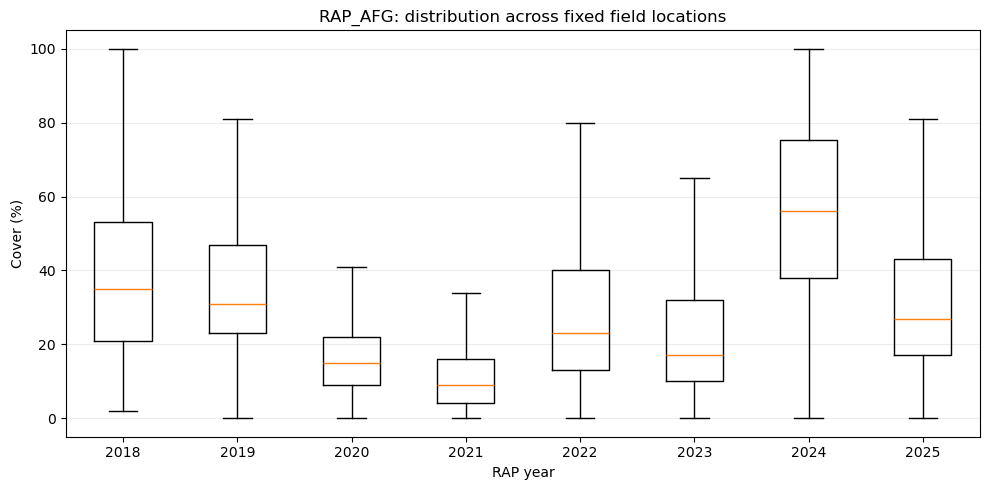

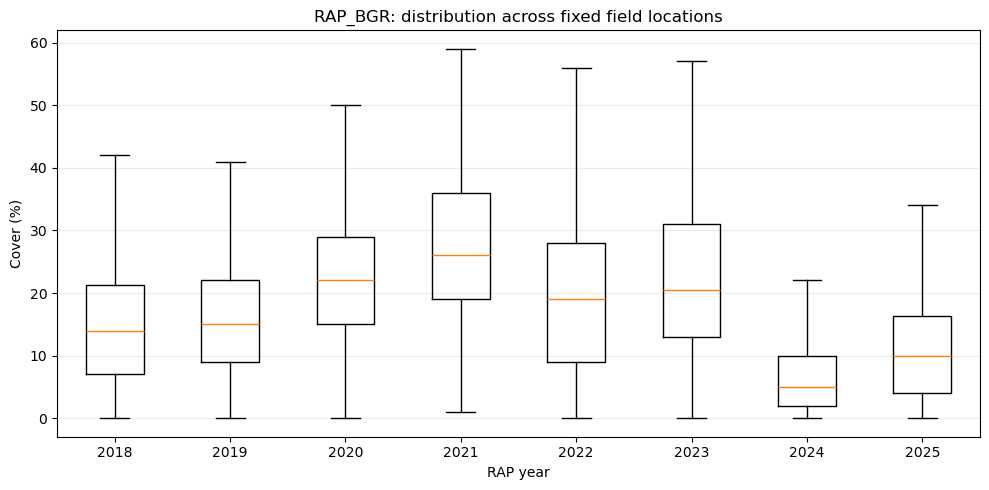

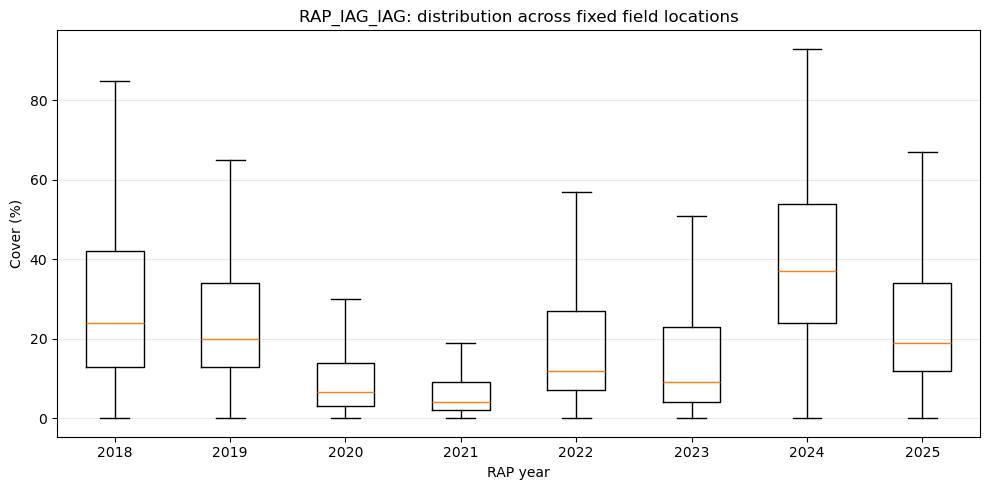

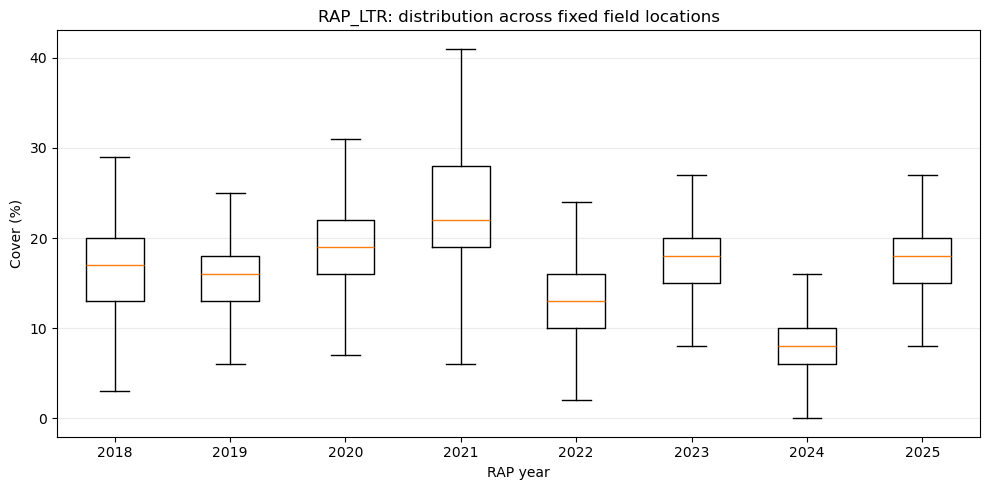

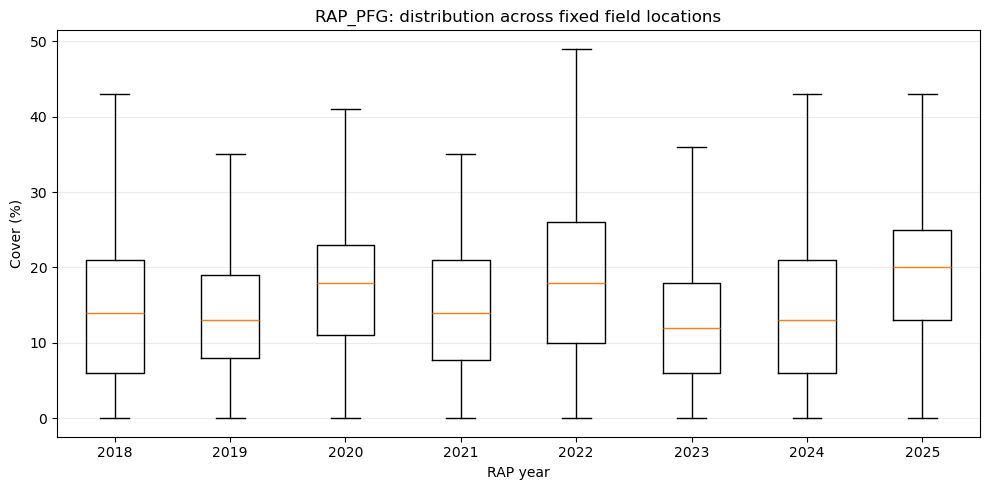

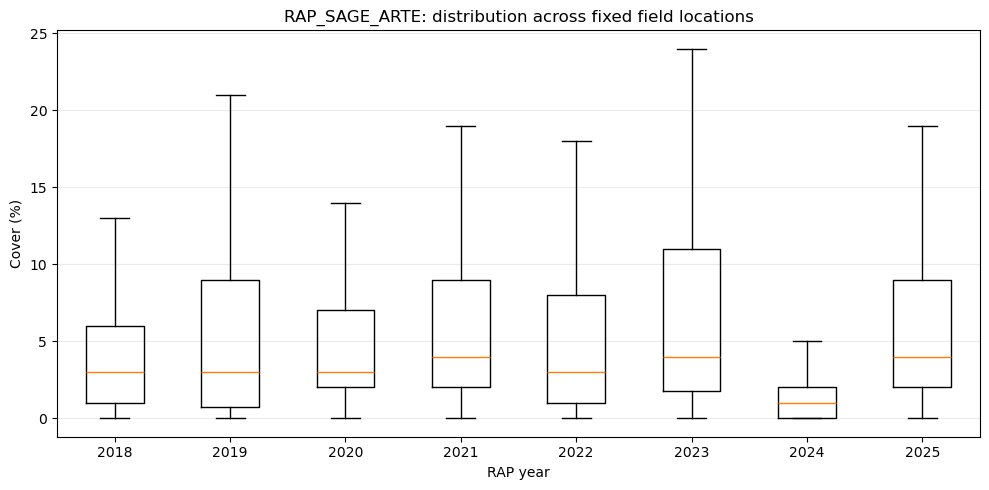

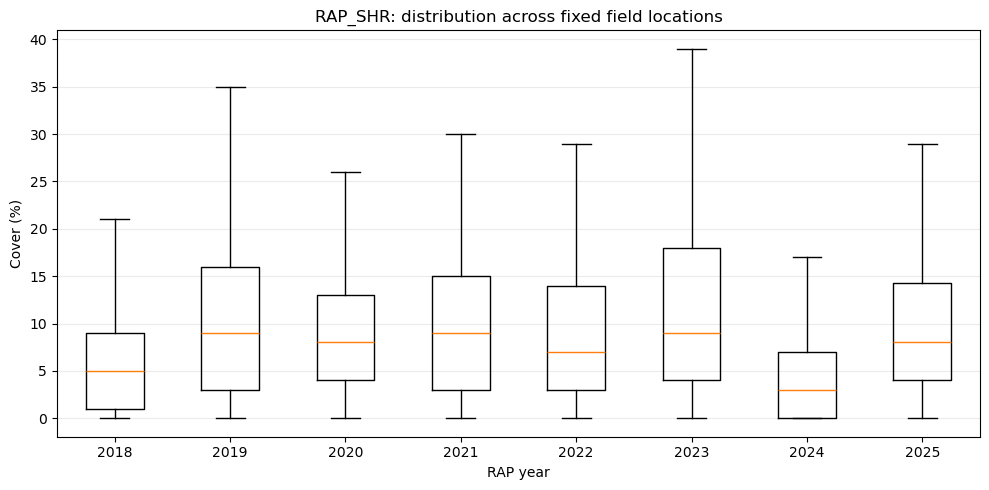

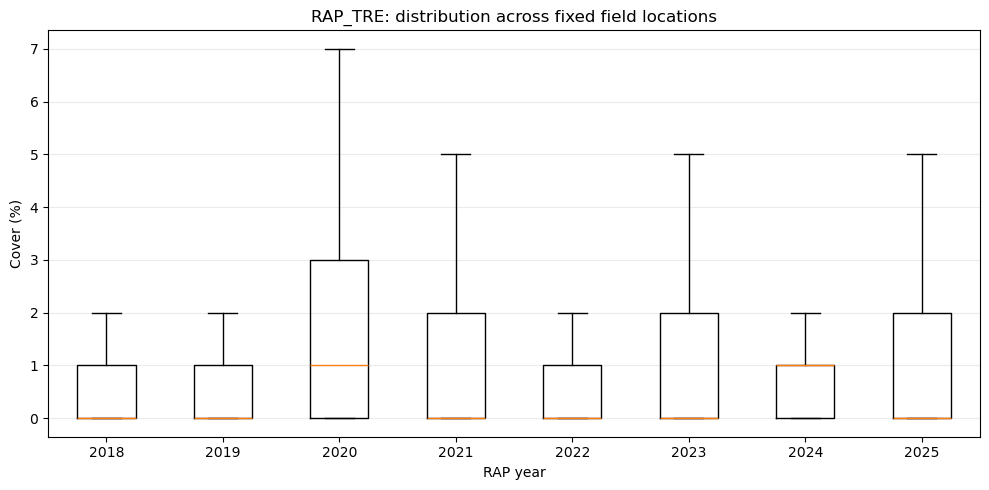

In [10]:

# One figure per RAP variable: annual boxplots at the same fixed positions.
for var in RAP_VARS:
    years = sorted(rap[RAP_YEAR].dropna().unique())
    data = [
        rap.loc[rap[RAP_YEAR].eq(year), var].dropna().values
        for year in years
    ]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.boxplot(data, tick_labels=[str(int(y)) for y in years], showfliers=False)
    ax.set_title(f"{var}: distribution across fixed field locations")
    ax.set_xlabel("RAP year")
    ax.set_ylabel("Cover (%)")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()


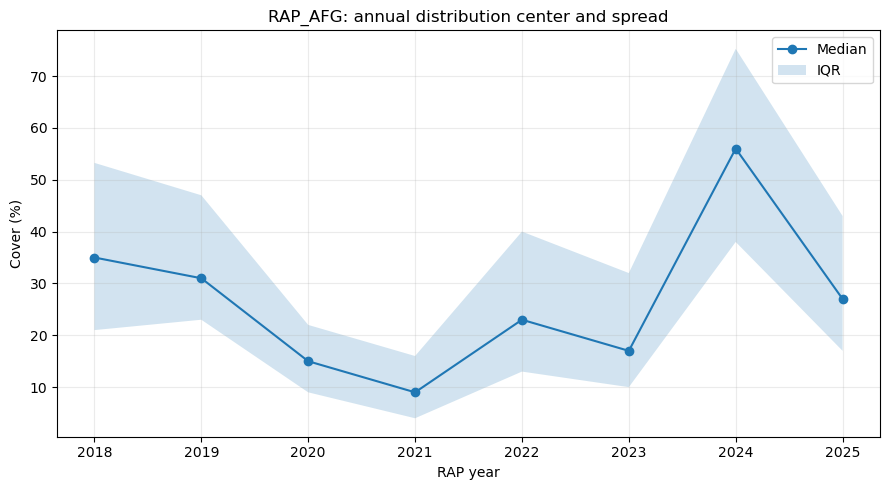

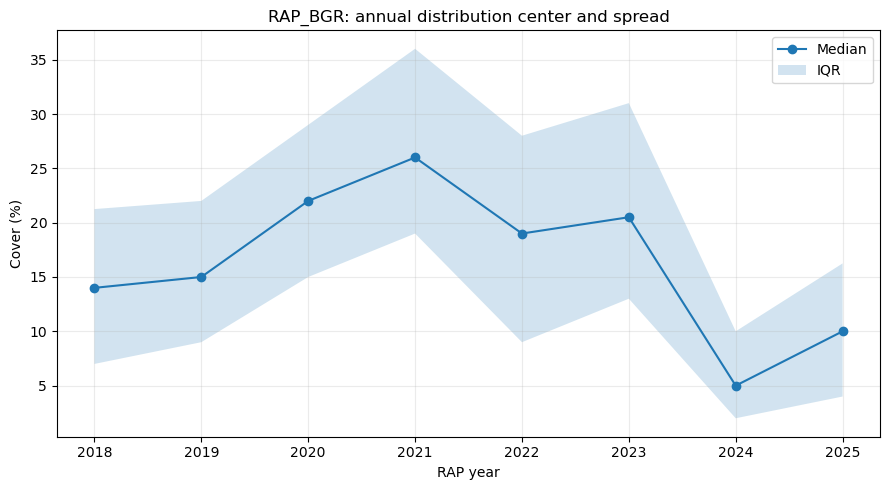

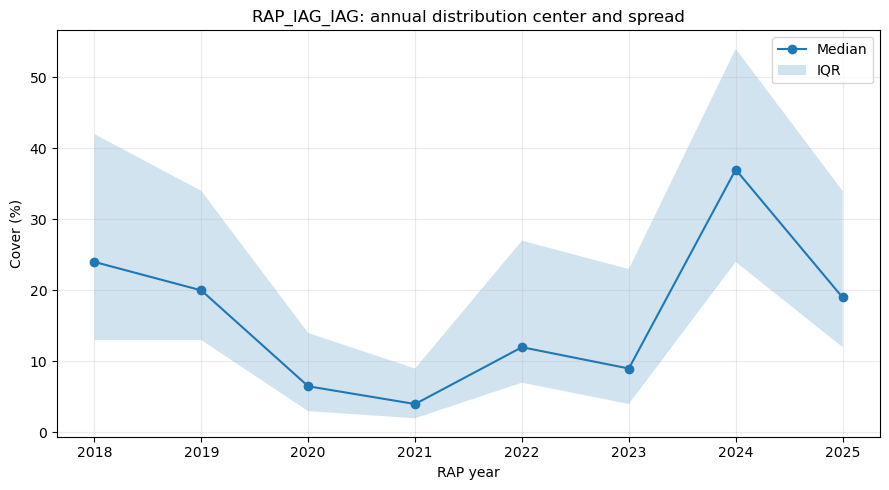

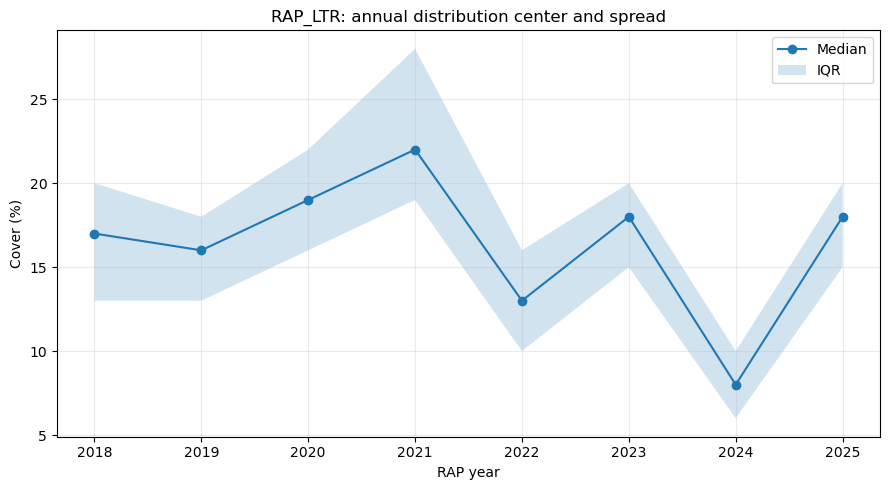

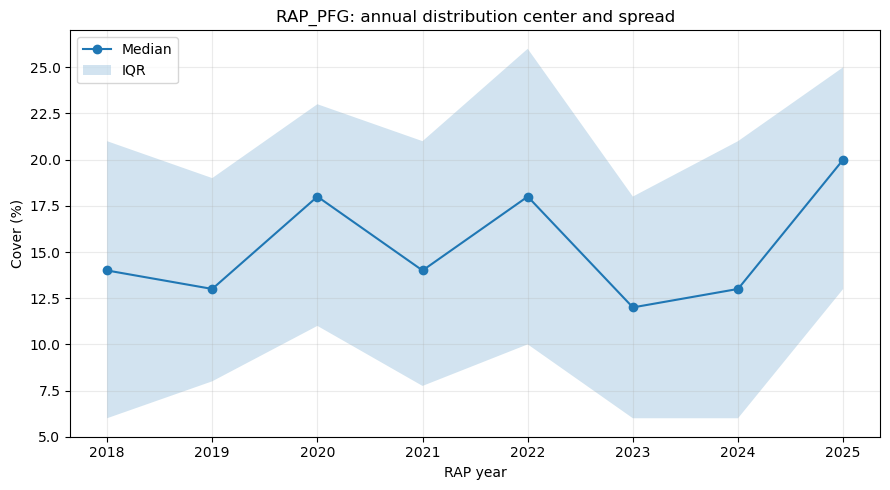

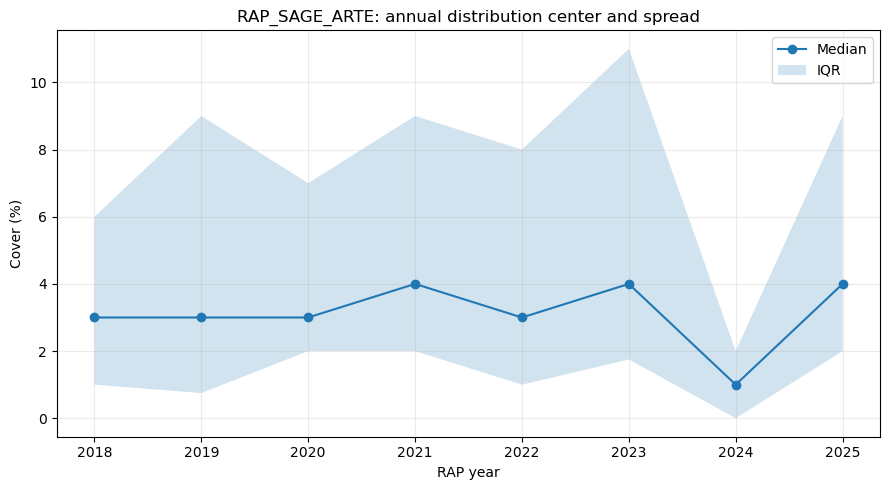

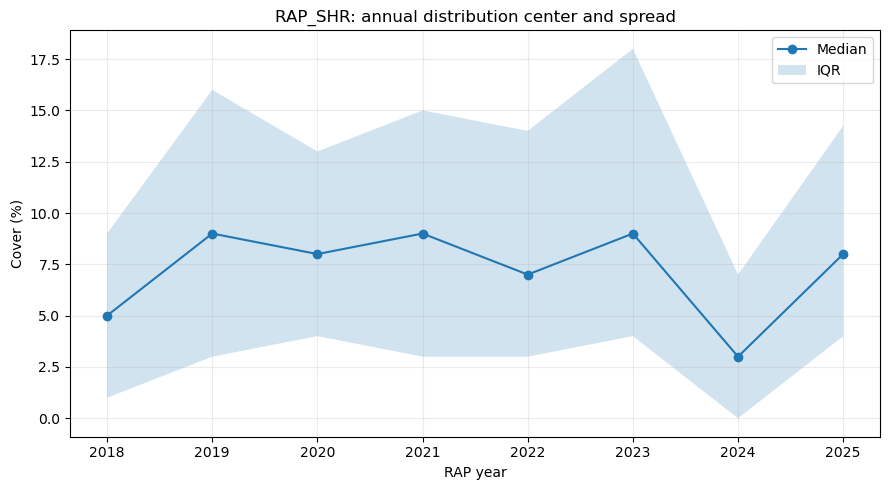

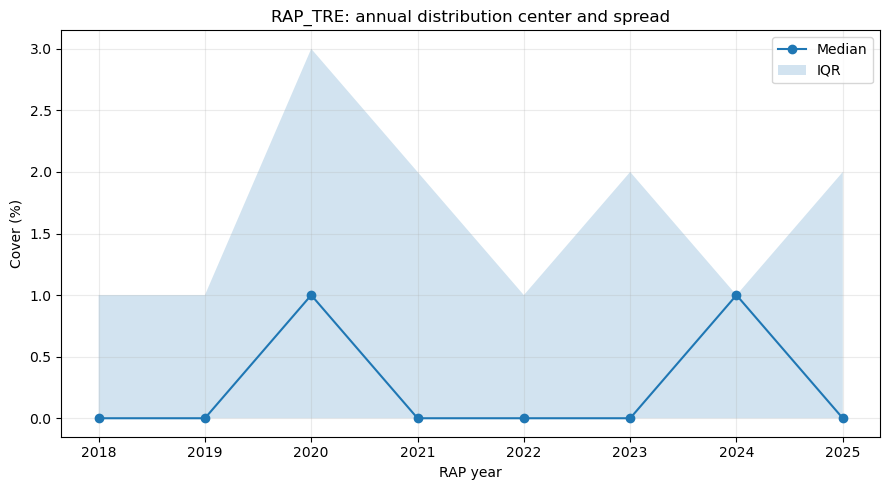

In [11]:

# Median and interquartile range through time.
for var in RAP_VARS:
    s = summary_tables[var]

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(s[RAP_YEAR], s["median"], marker="o", label="Median")
    ax.fill_between(
        s[RAP_YEAR].astype(float),
        s["q25"].astype(float),
        s["q75"].astype(float),
        alpha=0.2,
        label="IQR"
    )
    ax.set_title(f"{var}: annual distribution center and spread")
    ax.set_xlabel("RAP year")
    ax.set_ylabel("Cover (%)")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()



## 6. Change through time at fixed positions

A stable *distribution* could conceal substantial reshuffling among individual plots. The next diagnostics therefore operate within plots.

We quantify:

\[
\Delta x_{i,t} = x_{i,t} - x_{i,t-1}
\]

for plot \(i\), and inspect both the distribution of annual changes and the persistence of plot rankings.


In [12]:

# Sort and calculate year-to-year change within each monitored plot × field-year record.
rap = rap.sort_values([RECORD_ID, RAP_YEAR]).copy()

delta_cols = []

for var in RAP_VARS:
    dcol = f"d_{var}"

    rap[dcol] = (
        rap.groupby(RECORD_ID, sort=False)[var]
           .diff()
    )

    delta_cols.append(dcol)

delta_summary_rows = []

for var, dcol in zip(RAP_VARS, delta_cols):
    tmp = rap[[RAP_YEAR, dcol]].dropna()

    s = (
        tmp.groupby(RAP_YEAR)[dcol]
           .agg(
               n="count",
               mean_change="mean",
               median_change="median",
               mean_abs_change=lambda x: np.mean(np.abs(x)),
               q05=lambda x: x.quantile(0.05),
               q25=lambda x: x.quantile(0.25),
               q75=lambda x: x.quantile(0.75),
               q95=lambda x: x.quantile(0.95),
           )
           .reset_index()
    )

    s.insert(0, "variable", var)
    delta_summary_rows.append(s)

delta_summary = pd.concat(
    delta_summary_rows,
    ignore_index=True
)

display(delta_summary.head(20))


,variable,RAP_Year,n,mean_change,median_change,mean_abs_change,q05,q25,q75,q95
0,RAP_AFG,2019,960,-4.150000,-2.0,12.193750,-33.05,-13.0,6.0,16.00
1,RAP_AFG,2020,960,-18.162500,-17.0,18.660417,-42.00,-25.0,-9.0,-1.00
2,RAP_AFG,2021,960,-5.286458,-5.0,7.886458,-19.00,-10.0,-1.0,9.00
3,RAP_AFG,2022,960,16.230208,12.0,16.538542,1.00,7.0,24.0,42.00
4,RAP_AFG,2023,960,-4.727083,-4.0,9.658333,-26.00,-12.0,2.0,14.00
5,RAP_AFG,2024,960,33.620833,31.0,34.929167,-3.00,18.0,48.0,77.00
6,RAP_AFG,2025,960,-25.580208,-25.0,25.778125,-49.00,-35.0,-16.0,-5.00
7,RAP_BGR,2019,960,1.877083,2.0,4.960417,-9.00,-1.0,5.0,12.00
8,RAP_BGR,2020,960,6.178125,7.0,7.405208,-5.00,3.0,10.0,16.00
9,RAP_BGR,2021,960,4.723958,4.0,6.444792,-5.00,0.0,9.0,18.00


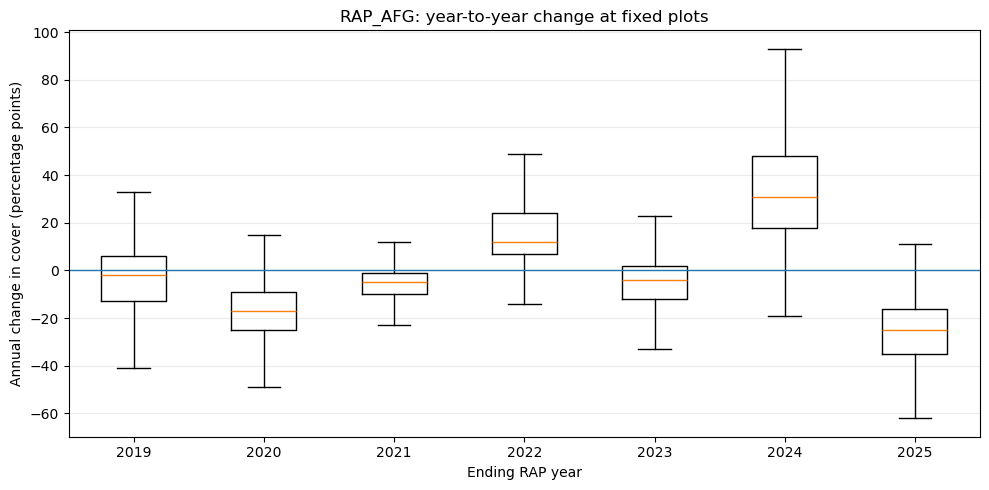

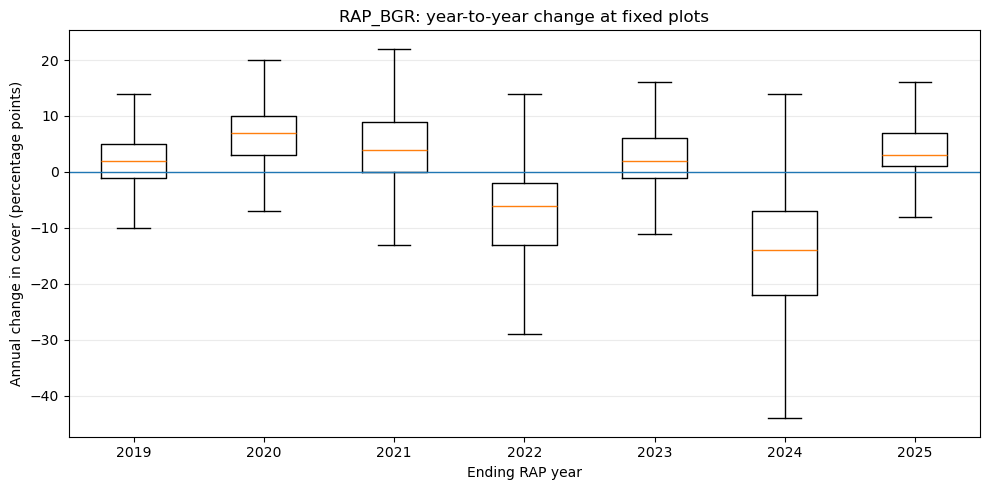

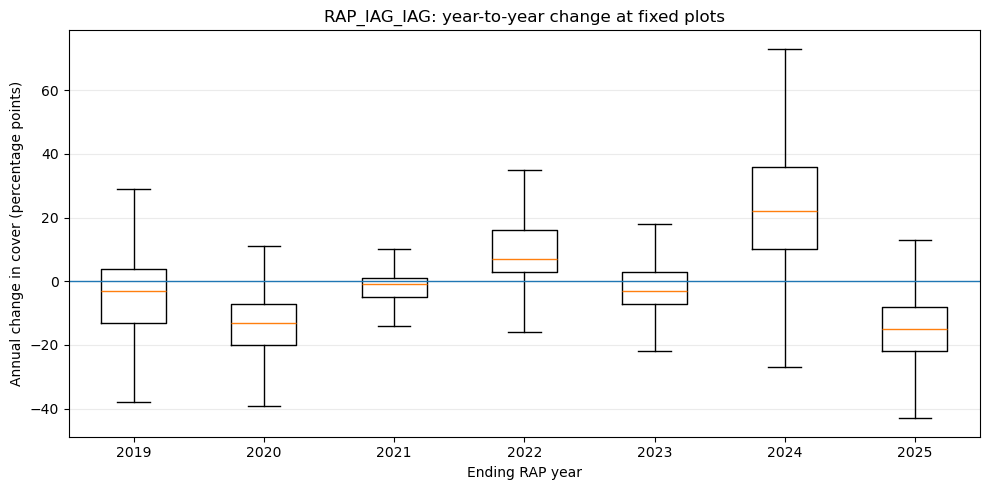

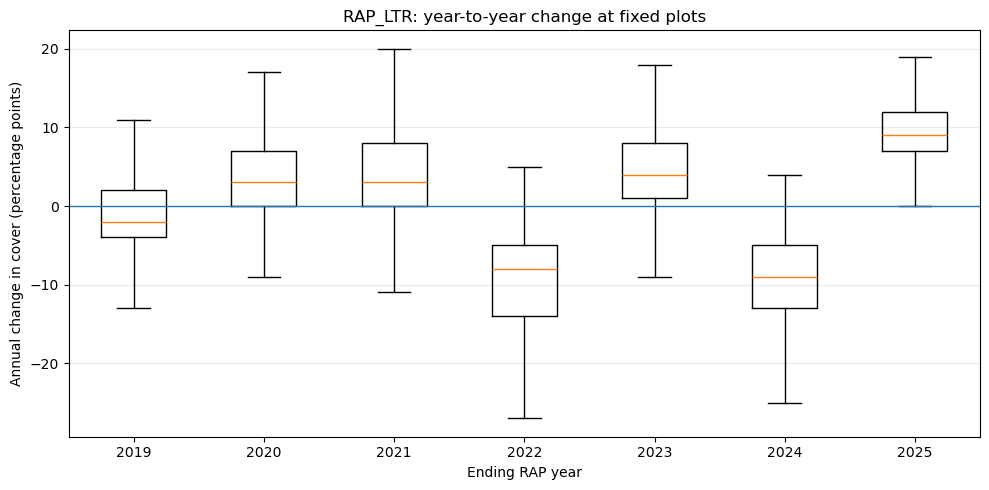

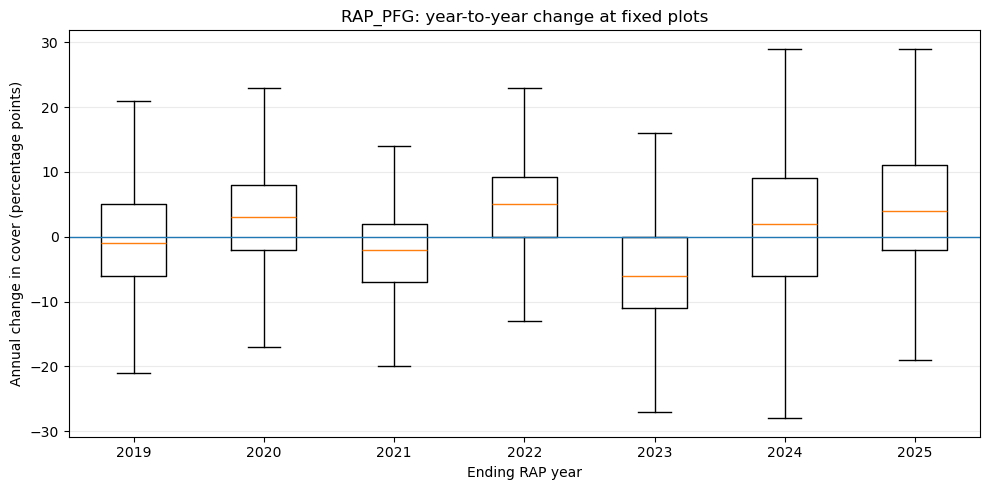

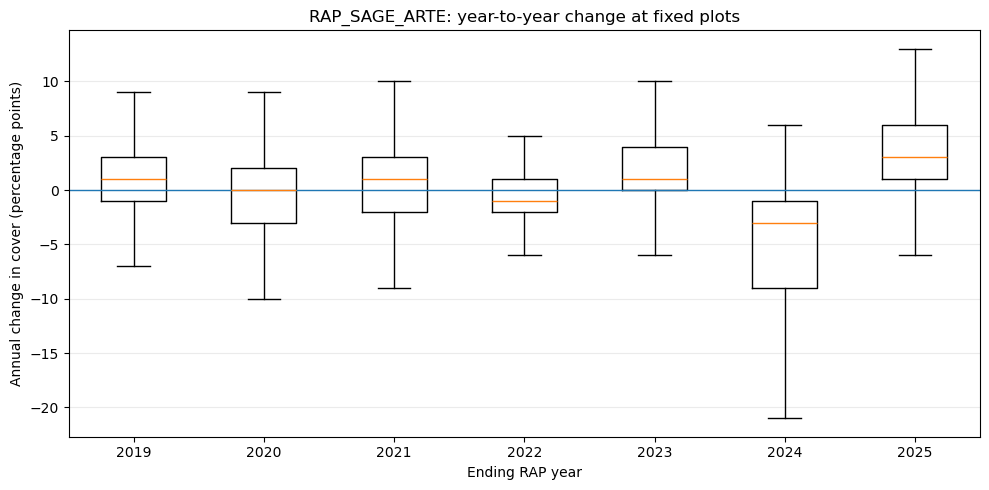

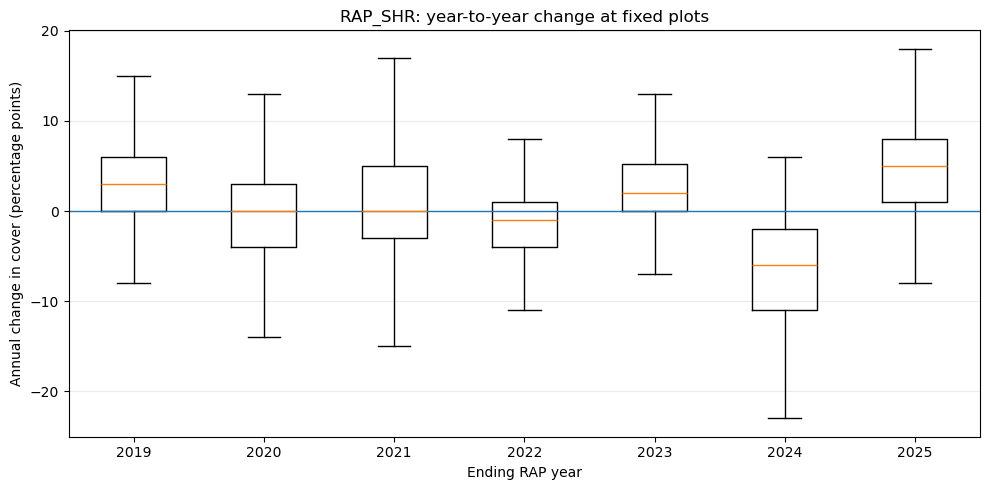

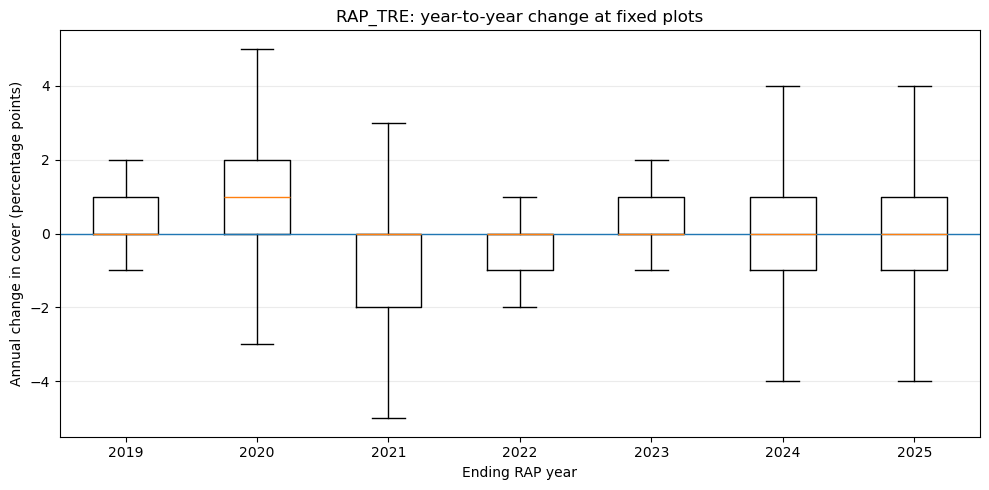

In [13]:

for var, dcol in zip(RAP_VARS, delta_cols):
    years = sorted(rap.loc[rap[dcol].notna(), RAP_YEAR].unique())
    data = [
        rap.loc[rap[RAP_YEAR].eq(year), dcol].dropna().values
        for year in years
    ]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.boxplot(data, tick_labels=[str(int(y)) for y in years], showfliers=False)
    ax.axhline(0, linewidth=1)
    ax.set_title(f"{var}: year-to-year change at fixed plots")
    ax.set_xlabel("Ending RAP year")
    ax.set_ylabel("Annual change in cover (percentage points)")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()



## 7. Temporal consistency / rank stability

If Snake River Plain errors are spatially structured but reasonably consistent through time, plots that RAP considers "high" or "low" for a cover variable should tend to retain that relative position.

We therefore calculate **Spearman rank correlation** between consecutive years. This is deliberately separate from agreement with field measurements.

High adjacent-year Spearman correlation means the spatial ordering of plots is stable; it does **not** establish that the absolute cover values are correct.


In [14]:

rank_rows = []

for var in RAP_VARS:

    wide = rap.pivot_table(
        index=RECORD_ID,
        columns=RAP_YEAR,
        values=var,
        aggfunc="first"
    )

    years = sorted(wide.columns)

    for y0, y1 in zip(years[:-1], years[1:]):

        pair = wide[[y0, y1]].dropna()

        if len(pair) >= 3:
            rho, p = stats.spearmanr(
                pair[y0],
                pair[y1]
            )
        else:
            rho, p = np.nan, np.nan

        rank_rows.append({
            "variable": var,
            "year_0": int(y0),
            "year_1": int(y1),
            "n": len(pair),
            "spearman_rho": rho,
            "p_value": p
        })

rank_stability = pd.DataFrame(rank_rows)

display(rank_stability)


,variable,year_0,year_1,n,spearman_rho,p_value
0,RAP_AFG,2018,2019,960,0.722728,7.109175e-156
1,RAP_AFG,2019,2020,960,0.689652,1.916184e-136
2,RAP_AFG,2020,2021,960,0.689978,1.270457e-136
3,RAP_AFG,2021,2022,960,0.784497,5.202761e-201
4,RAP_AFG,2022,2023,960,0.769803,5.322996e-189
5,RAP_AFG,2023,2024,960,0.460204,1.732042e-51
6,RAP_AFG,2024,2025,960,0.828229,3.515437e-243
7,RAP_BGR,2018,2019,960,0.779793,4.591228e-197
8,RAP_BGR,2019,2020,960,0.811291,1.523494e-225
9,RAP_BGR,2020,2021,960,0.805896,2.686365e-220


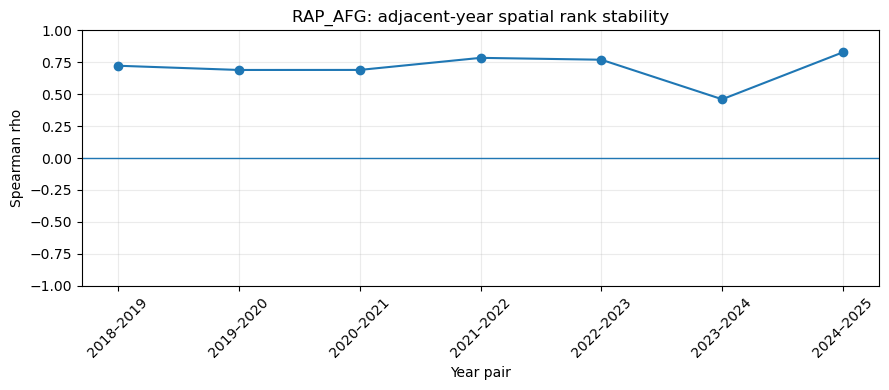

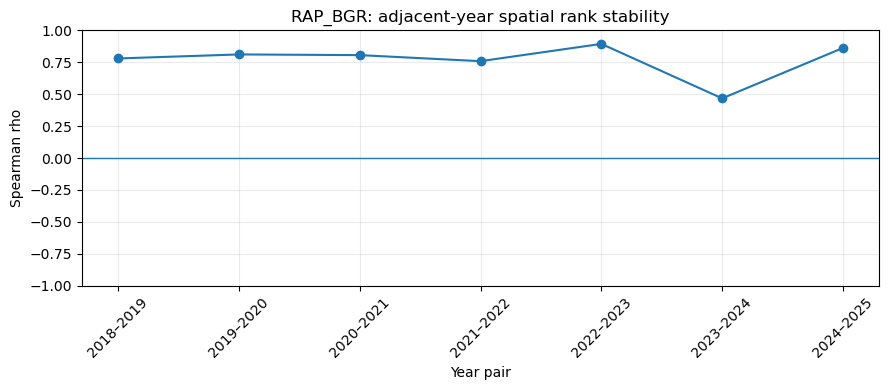

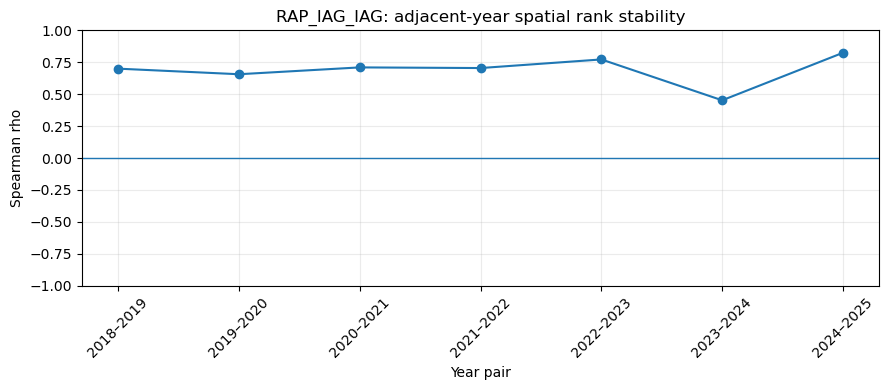

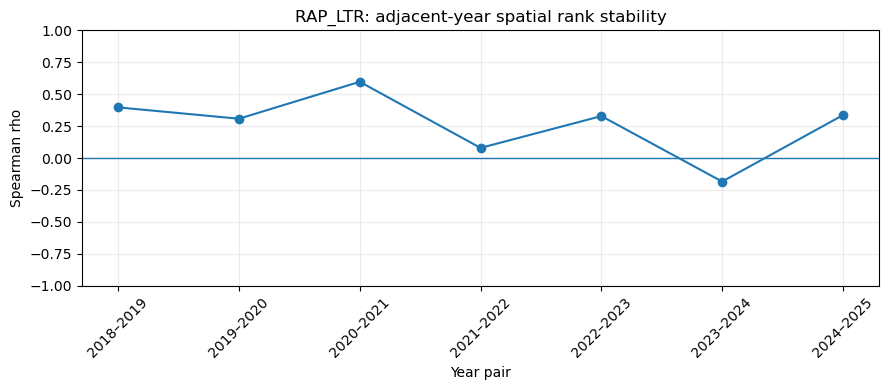

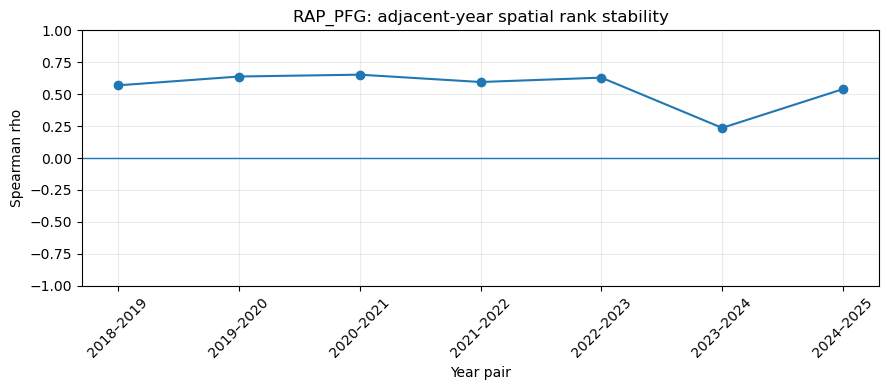

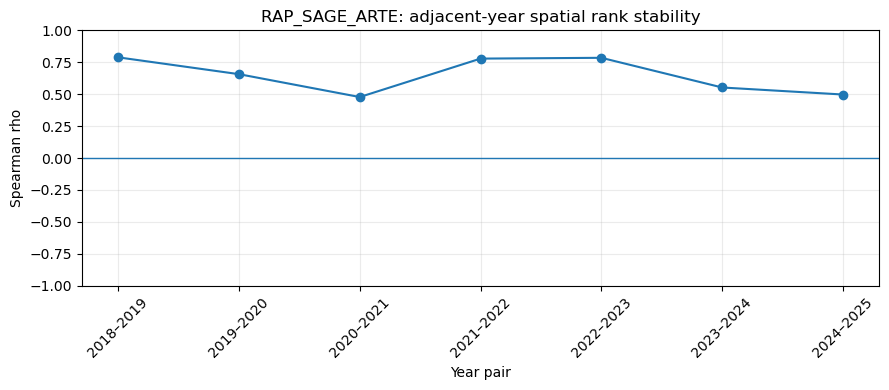

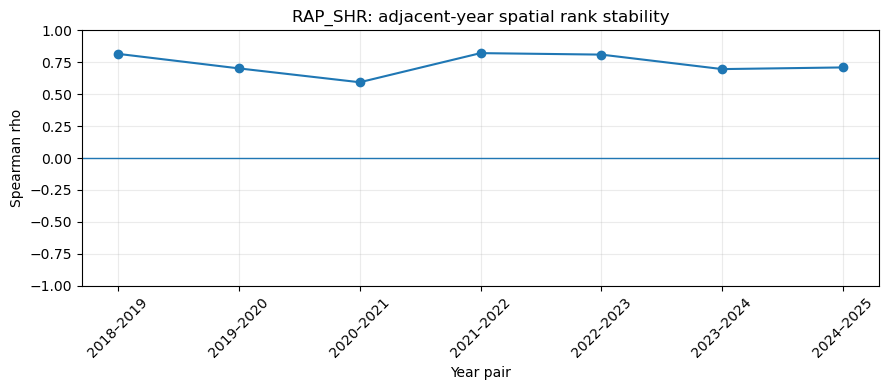

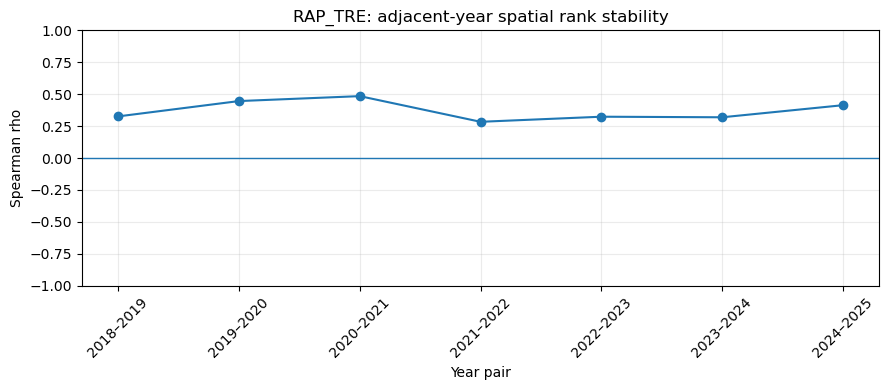

In [15]:

for var in RAP_VARS:
    s = rank_stability.loc[rank_stability["variable"].eq(var)].copy()
    if s.empty:
        continue

    labels = s["year_0"].astype(str) + "–" + s["year_1"].astype(str)

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(labels, s["spearman_rho"], marker="o")
    ax.set_ylim(-1, 1)
    ax.axhline(0, linewidth=1)
    ax.set_title(f"{var}: adjacent-year spatial rank stability")
    ax.set_xlabel("Year pair")
    ax.set_ylabel("Spearman rho")
    ax.grid(alpha=0.25)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()



## 8. Persistent spatial signal versus temporal variability

For each plot and RAP variable, calculate:

- temporal mean
- temporal SD
- temporal range
- coefficient of variation where meaningful

This identifies locations that are consistently assigned similar values versus locations where RAP fluctuates substantially through time.


In [16]:

plot_temporal = []

for var in RAP_VARS:

    g = (
        rap.groupby(RECORD_ID)[var]
           .agg(
               temporal_mean="mean",
               temporal_sd="std",
               temporal_min="min",
               temporal_max="max",
               n_years="count"
           )
           .reset_index()
    )

    g["temporal_range"] = (
        g["temporal_max"]
        - g["temporal_min"]
    )

    g["temporal_cv"] = np.where(
        g["temporal_mean"].abs() > 1e-9,
        g["temporal_sd"] / g["temporal_mean"].abs(),
        np.nan
    )

    g.insert(1, "variable", var)
    plot_temporal.append(g)

plot_temporal = pd.concat(
    plot_temporal,
    ignore_index=True
)

display(plot_temporal.head())


,PlotYearID,variable,temporal_mean,temporal_sd,temporal_min,temporal_max,n_years,temporal_range,temporal_cv
0,2016_100,RAP_AFG,33.125,20.917781,9,77,8,68,0.631480
1,2016_101,RAP_AFG,36.500,23.844736,9,81,8,72,0.653280
2,2016_102,RAP_AFG,45.500,24.000000,12,96,8,84,0.527473
3,2016_103,RAP_AFG,43.625,20.934848,15,84,8,69,0.479882
4,2016_104,RAP_AFG,38.375,21.131814,20,82,8,62,0.550666



## 9. Isolate the RAP observation corresponding to the field monitoring year

This is the paired dataset for RAP-versus-field evaluation:

\[
\text{RAP year} = \text{field monitoring year}
\]

Only field years with a corresponding RAP 10 m year can contribute. Thus 2016 field observations cannot be directly paired to RAP 10 m.


In [17]:

# Retain the RAP observation corresponding to each monitored record's field year.
#
# Each PlotYearID is a unique field monitoring record. This comparison therefore
# pairs that record only with RAP from the same calendar year.
monitored = rap.loc[
    rap[RAP_YEAR].notna()
    & rap[FIELD_YEAR].notna()
    & rap[RAP_YEAR].eq(rap[FIELD_YEAR])
].copy()

print(f"Matched monitored-year RAP records: {len(monitored):,}")
print(f"Unique matched {RECORD_ID}: {monitored[RECORD_ID].nunique():,}")
print("Field years represented:")

display(
    monitored[FIELD_YEAR]
    .value_counts()
    .sort_index()
    .to_frame("n")
)


Matched monitored-year RAP records: 236
Unique matched PlotYearID: 236
Field years represented:


,n
year,
2018,118
2025,118



## 10. Field-cover mapping

The vegetation observations are now joined directly to `rap` by `PlotYearID`,
so the monitored-year comparison can use the observed functional-group cover
columns without another merge.

Configure only relationships that are biologically defensible.

**Do not treat similarly named variables as automatically homologous.**
In particular, RAP AFG/PFG and the field-derived annual/perennial groups differ
in definition. Those comparisons can still be explored, but they should be
labeled as comparisons between related constructs rather than identical
measurements.

The dictionary format is:

```python
FIELD_RAP_MAP = {
    "field_column": "RAP_column"
}
```


In [18]:

# Inspect potentially relevant field-cover columns retained in the GEE export.
possible_field_cols = [
    c for c in monitored.columns
    if c not in RAP_VARS
    and c not in metadata_cols
    and pd.to_numeric(monitored[c], errors="coerce").notna().sum() > 0
]

print("Numeric non-RAP columns available for possible field comparison:")
for c in possible_field_cols:
    print("  ", c)


Numeric non-RAP columns available for possible field comparison:
   ARTR2
   CHVI8
   ERNA10
   KRLA2
   ATCO
   PUTR2
   BAPR5
   POSE
   BRTE
   AGCR
   PSSP6
   ACTH7
   HECO
   ELEL5
   ACHY
   ELYMUS
   GRSP
   GUSA
   SAVE4
   SHRUB
   BRBR
   PBG
   ONAC
   CHJU
   FORB
   BRASS
   SATR12D
   CETE5
   LEPE2
   NOTR
   UNK.PLANT
   OTHER
   LITTER
   BAREGROUND
   BASC
   SATR12
   BIOCRUST
   HEAN3
   SIAL2D
   LASE
   SIAL2
   CEST8
   CHVI8D
   DESO2
   VUOC
   ARTR2D
   AMAL
   TEGL
   BAPR5D
   LECI4
   EPBR3
   DEPI
   TACA8
   CREPI
   FEID
   EUMA7
   ATCA2
   SPGR2
   PSJU3
   BAAM4
   TRDU
   MACA2
   GAYOP
   SPCR
   TRMA3
   ATCOD
   VUBR
   TESP2
   ATCA2D
   BASA3
   total_cover
   ARTR_FG
   BAREGROUND_FG
   BIOCRUST_FG
   EAG_FG
   EF_FG
   LITTER_FG
   NPF_FG
   OTHER_FG
   PBG_FG
   SHRUB_FG
   SHRUB_total
   total_cover_fg
   AMAC2
   ARAR8
   CADR
   CICY
   DISP
   ERCI6
   ERTR13
   HAGL
   PHHA
   PHLO2
   PIDE4
   PSLA3
   ROCK
   SHIT
   TRASH
   VULPI
  

In [19]:

# ---------------------------------------------------------------------------
# FIELD ↔ RAP VARIABLE MAPPING
# ---------------------------------------------------------------------------
#
# Start with the cleanest ecological correspondences.
#
# ARTR_FG is a direct sagebrush functional group in the field table.
# SHRUB_FG represents non-ARTR shrub cover in the vegetation clustering,
# whereas RAP_SHR is total shrub cover. Therefore total field shrub is
# constructed below as ARTR_FG + SHRUB_FG.
#
# AFG/PFG comparisons are left commented because the field and RAP definitions
# are not identical.

rap["SHRUB_TOTAL_FG"] = (
    pd.to_numeric(rap["ARTR_FG"], errors="coerce").fillna(0)
    + pd.to_numeric(rap["SHRUB_FG"], errors="coerce").fillna(0)
)

FIELD_RAP_MAP = {
    "ARTR_FG": "RAP_SAGE_ARTE",
    "SHRUB_TOTAL_FG": "RAP_SHR",
    "BAREGROUND_FG": "RAP_BGR",
    "LITTER_FG": "RAP_LTR",
    "EAG_FG": "RAP_IAG_IAG",

    # Related but not strictly homologous constructs:
    # "PBG_FG": "RAP_PFG",
    # "EAG_FG": "RAP_AFG",
}

FIELD_RAP_MAP


{'ARTR_FG': 'RAP_SAGE_ARTE',
 'SHRUB_TOTAL_FG': 'RAP_SHR',
 'BAREGROUND_FG': 'RAP_BGR',
 'LITTER_FG': 'RAP_LTR',
 'EAG_FG': 'RAP_IAG_IAG'}


## 11. Paired monitored-year agreement

For each enabled field/RAP pair we calculate:

- mean bias: \(\overline{RAP - Field}\)
- MAE
- RMSE
- Pearson \(r\)
- Spearman \(\rho\)

Bias is especially important here because the working hypothesis is that national-product errors may be **systematic but consistent** in the Snake River Plain.


In [20]:

def agreement_stats(df, field_col, rap_col):
    pair = df[[field_col, rap_col]].copy()
    pair[field_col] = pd.to_numeric(pair[field_col], errors="coerce")
    pair[rap_col] = pd.to_numeric(pair[rap_col], errors="coerce")
    pair = pair.dropna()

    if len(pair) == 0:
        return None

    err = pair[rap_col] - pair[field_col]

    if len(pair) >= 3:
        pearson_r, pearson_p = stats.pearsonr(pair[field_col], pair[rap_col])
        spearman_rho, spearman_p = stats.spearmanr(pair[field_col], pair[rap_col])
    else:
        pearson_r = pearson_p = spearman_rho = spearman_p = np.nan

    return {
        "field_variable": field_col,
        "rap_variable": rap_col,
        "n": len(pair),
        "field_mean": pair[field_col].mean(),
        "rap_mean": pair[rap_col].mean(),
        "bias_RAP_minus_field": err.mean(),
        "MAE": np.abs(err).mean(),
        "RMSE": np.sqrt(np.mean(err**2)),
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_rho": spearman_rho,
        "Spearman_p": spearman_p,
    }


agreement_rows = []

for field_col, rap_col in FIELD_RAP_MAP.items():
    if field_col not in monitored.columns:
        print(f"Skipping missing field column: {field_col}")
        continue
    if rap_col not in monitored.columns:
        print(f"Skipping missing RAP column: {rap_col}")
        continue

    out = agreement_stats(monitored, field_col, rap_col)
    if out is not None:
        agreement_rows.append(out)

agreement = pd.DataFrame(agreement_rows)

if agreement.empty:
    print("No field/RAP mappings enabled yet. Edit FIELD_RAP_MAP above.")
else:
    display(agreement)


Skipping missing field column: SHRUB_TOTAL_FG


,field_variable,rap_variable,n,field_mean,rap_mean,bias_RAP_minus_field,MAE,RMSE,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,ARTR_FG,RAP_SAGE_ARTE,224,2.309970,4.799107,2.489137,4.861657,7.454226,0.388020,1.831593e-09,0.383048,3.056486e-09
1,BAREGROUND_FG,RAP_BGR,224,22.920430,14.401786,-8.518644,12.630016,17.679686,0.678448,1.459531e-31,0.642129,1.958009e-27
2,LITTER_FG,RAP_LTR,224,15.667644,16.209821,0.542178,7.848437,10.185415,0.460522,3.694886e-13,0.487005,9.637822e-15
3,EAG_FG,RAP_IAG_IAG,224,24.382331,26.459821,2.077490,16.215030,21.180314,0.672185,8.275027e-31,0.596138,6.055390e-23


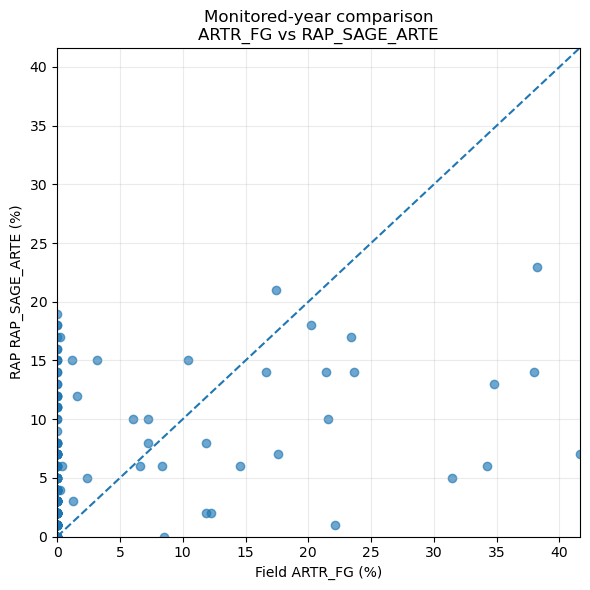

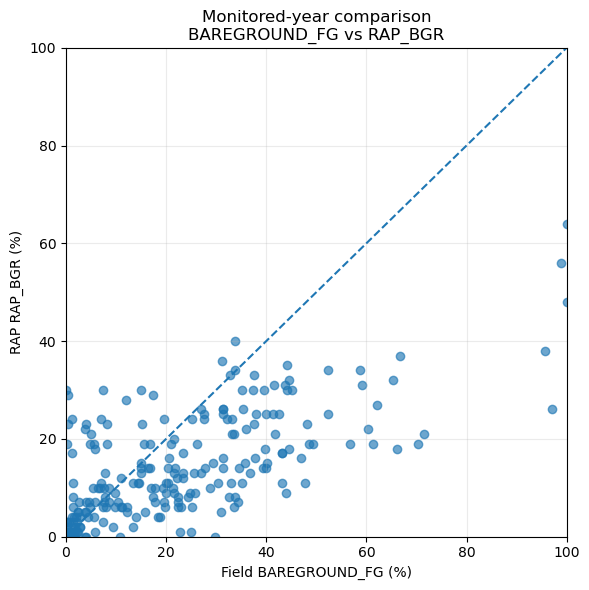

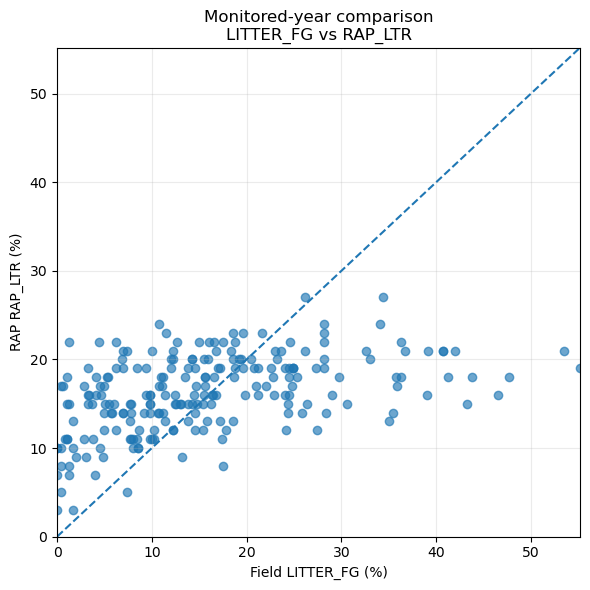

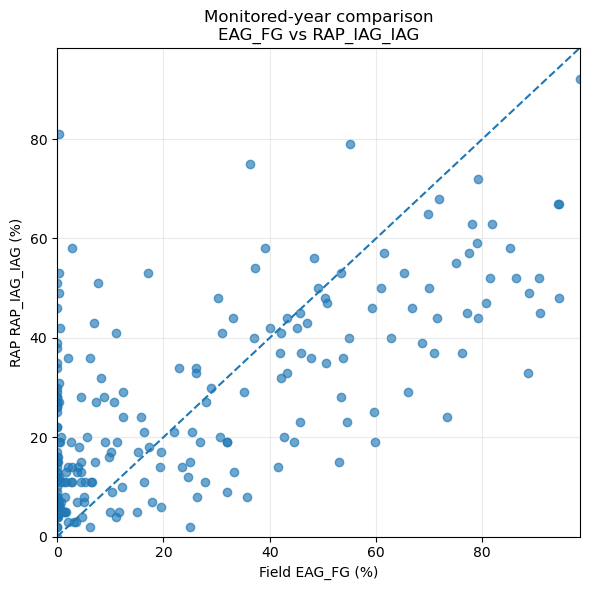

In [21]:

# One observed-vs-RAP scatter plot per enabled comparison.
for field_col, rap_col in FIELD_RAP_MAP.items():

    if field_col not in monitored.columns or rap_col not in monitored.columns:
        continue

    pair = monitored[[field_col, rap_col, FIELD_YEAR]].copy()
    pair[field_col] = pd.to_numeric(pair[field_col], errors="coerce")
    pair[rap_col] = pd.to_numeric(pair[rap_col], errors="coerce")
    pair = pair.dropna()

    if pair.empty:
        continue

    lim_min = min(pair[field_col].min(), pair[rap_col].min(), 0)
    lim_max = max(pair[field_col].max(), pair[rap_col].max())

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(pair[field_col], pair[rap_col], alpha=0.65)
    ax.plot([lim_min, lim_max], [lim_min, lim_max], linestyle="--")
    ax.set_xlim(lim_min, lim_max)
    ax.set_ylim(lim_min, lim_max)
    ax.set_xlabel(f"Field {field_col} (%)")
    ax.set_ylabel(f"RAP {rap_col} (%)")
    ax.set_title(f"Monitored-year comparison\n{field_col} vs {rap_col}")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()



## 12. Bias through monitoring years

A constant offset is very different from a changing offset. For each defensible field/RAP pair, inspect:

\[
e_{i,t}=RAP_{i,t}-Field_{i,t}
\]

by monitoring year.

With the available RAP 10 m record, this will primarily evaluate monitored years from 2018 onward.


In [22]:

bias_by_year_rows = []

for field_col, rap_col in FIELD_RAP_MAP.items():

    if field_col not in monitored.columns or rap_col not in monitored.columns:
        continue

    tmp = monitored[[FIELD_YEAR, field_col, rap_col]].copy()
    tmp[field_col] = pd.to_numeric(tmp[field_col], errors="coerce")
    tmp[rap_col] = pd.to_numeric(tmp[rap_col], errors="coerce")
    tmp = tmp.dropna()

    if tmp.empty:
        continue

    tmp["error"] = tmp[rap_col] - tmp[field_col]

    s = (
        tmp.groupby(FIELD_YEAR)["error"]
           .agg(
               n="count",
               mean_bias="mean",
               median_bias="median",
               MAE=lambda x: np.mean(np.abs(x)),
               RMSE=lambda x: np.sqrt(np.mean(x**2)),
               sd_error="std"
           )
           .reset_index()
    )

    s.insert(0, "field_variable", field_col)
    s.insert(1, "rap_variable", rap_col)
    bias_by_year_rows.append(s)

if bias_by_year_rows:
    bias_by_year = pd.concat(bias_by_year_rows, ignore_index=True)
    display(bias_by_year)
else:
    bias_by_year = pd.DataFrame()
    print("No enabled field/RAP mappings.")


,field_variable,rap_variable,year,n,mean_bias,median_bias,MAE,RMSE,sd_error
0,ARTR_FG,RAP_SAGE_ARTE,2018,107,1.004673,2.000000,3.900000,6.910987,6.869748
1,ARTR_FG,RAP_SAGE_ARTE,2025,117,3.846724,3.000000,5.741121,7.918475,6.951111
2,BAREGROUND_FG,RAP_BGR,2018,107,-13.957255,-12.473333,15.402453,20.391632,14.936489
3,BAREGROUND_FG,RAP_BGR,2025,117,-3.544872,-0.800000,10.094539,14.769852,14.399815
4,LITTER_FG,RAP_LTR,2018,107,0.216231,3.260000,9.205452,11.436904,11.488671
5,LITTER_FG,RAP_LTR,2025,117,0.840266,2.000000,6.607407,8.887936,8.886184
6,EAG_FG,RAP_IAG_IAG,2018,107,12.030343,11.000000,18.768224,23.709665,20.526982
7,EAG_FG,RAP_IAG_IAG,2025,117,-7.024691,-2.222222,13.880057,18.567919,17.261752


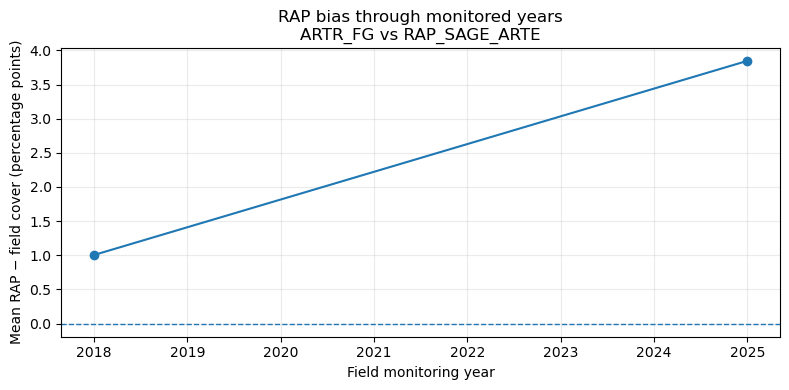

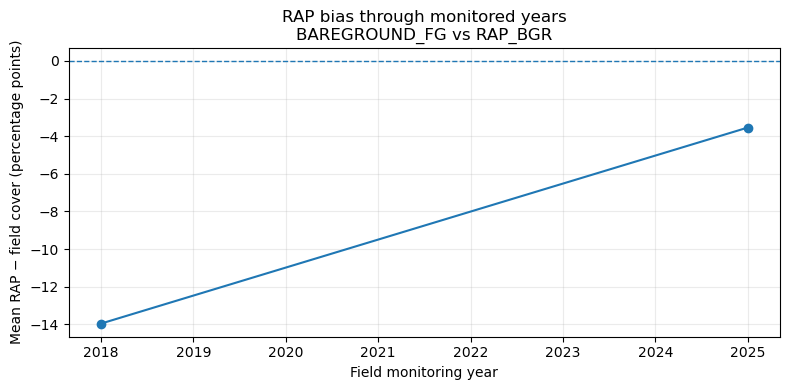

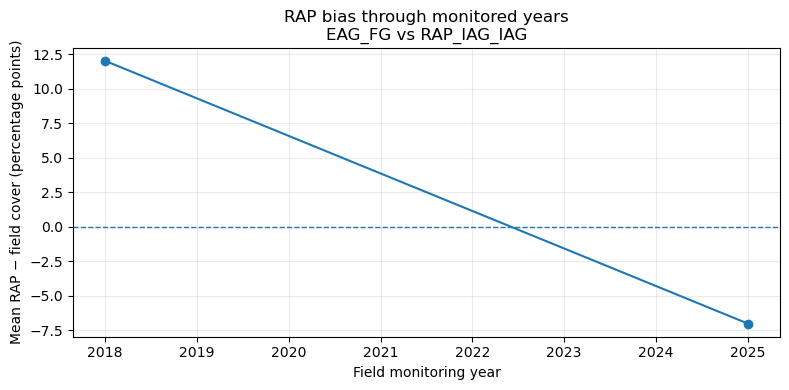

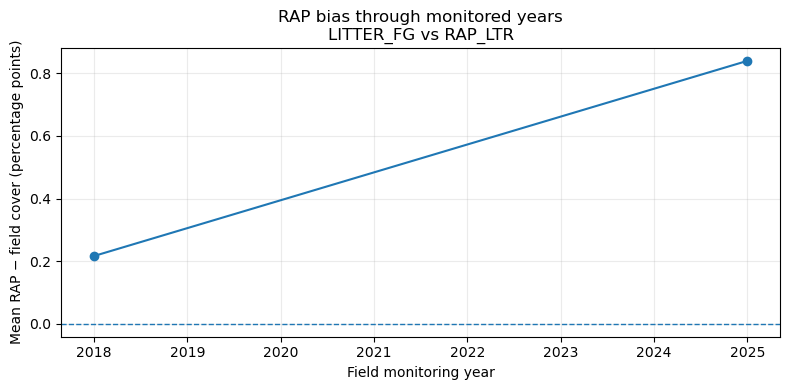

In [23]:

if not bias_by_year.empty:
    for (field_col, rap_col), s in bias_by_year.groupby(
        ["field_variable", "rap_variable"]
    ):
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(s[FIELD_YEAR], s["mean_bias"], marker="o")
        ax.axhline(0, linestyle="--", linewidth=1)
        ax.set_title(f"RAP bias through monitored years\n{field_col} vs {rap_col}")
        ax.set_xlabel("Field monitoring year")
        ax.set_ylabel("Mean RAP − field cover (percentage points)")
        ax.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()



## 13. Tree-cover diagnostic

Trees are effectively absent from the focal landscape. Therefore non-zero RAP tree cover is not treated as ecological signal here; it is a useful indicator of model allocation error.

If the tree error is relatively stable through time at fixed positions, that would support the idea that at least some RAP error is spatially persistent.


Tree diagnostic variable: RAP_TRE


,RAP_Year,n,mean,median,sd,q05,q25,q75,q95
0,2018,960,0.622917,0.0,1.241234,0.0,0.0,1.0,2.0
1,2019,960,0.868750,0.0,1.282538,0.0,0.0,1.0,3.0
2,2020,960,1.940625,1.0,2.366259,0.0,0.0,3.0,7.0
3,2021,960,1.268750,0.0,1.906758,0.0,0.0,2.0,6.0
4,2022,960,0.725000,0.0,0.948848,0.0,0.0,1.0,3.0
5,2023,960,1.347917,0.0,2.139015,0.0,0.0,2.0,6.0
6,2024,960,0.832292,1.0,1.025229,0.0,0.0,1.0,3.0
7,2025,960,1.269792,0.0,2.061900,0.0,0.0,2.0,6.0


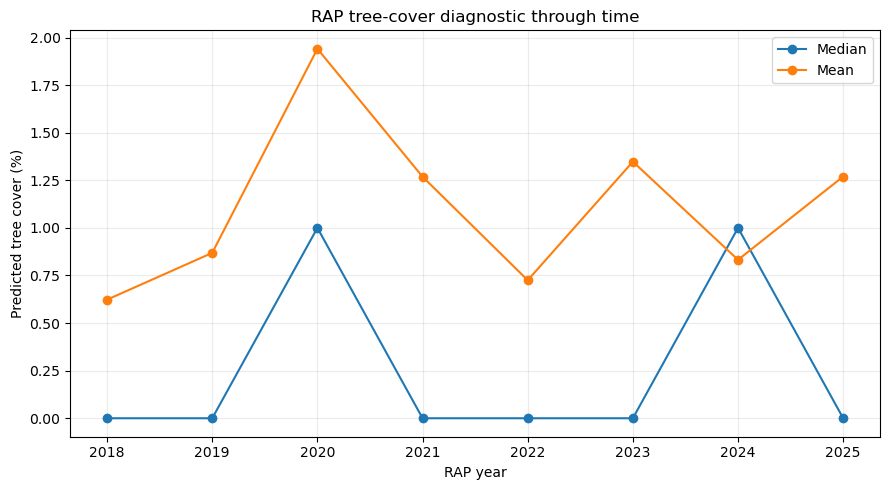

In [24]:

tree_candidates = [
    c for c in RAP_VARS
    if "TRE" in c.upper() or "TREE" in c.upper()
]

if not tree_candidates:
    print("No tree-cover band detected.")
else:
    tree_col = tree_candidates[0]
    print("Tree diagnostic variable:", tree_col)

    tree_summary = annual_summary(rap, tree_col)
    display(tree_summary)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(tree_summary[RAP_YEAR], tree_summary["median"], marker="o", label="Median")
    ax.plot(tree_summary[RAP_YEAR], tree_summary["mean"], marker="o", label="Mean")
    ax.set_title("RAP tree-cover diagnostic through time")
    ax.set_xlabel("RAP year")
    ax.set_ylabel("Predicted tree cover (%)")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()



## 14. Export analysis tables

These are small tabular outputs, so they can safely live with the analysis results rather than a raster scratch directory.


In [25]:

OUTPUT_DIR = RAP_DIR / "analysis_tables"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Annual distribution summaries
annual_out = []
for var, df in summary_tables.items():
    tmp = df.copy()
    tmp.insert(0, "variable", var)
    annual_out.append(tmp)

pd.concat(annual_out, ignore_index=True).to_csv(
    OUTPUT_DIR / "RAP10_annual_distribution_summary.csv",
    index=False
)

delta_summary.to_csv(
    OUTPUT_DIR / "RAP10_annual_change_summary.csv",
    index=False
)

rank_stability.to_csv(
    OUTPUT_DIR / "RAP10_adjacent_year_rank_stability.csv",
    index=False
)

plot_temporal.to_csv(
    OUTPUT_DIR / "RAP10_plot_temporal_stability.csv",
    index=False
)

if not agreement.empty:
    agreement.to_csv(
        OUTPUT_DIR / "RAP10_monitored_year_agreement.csv",
        index=False
    )

if not bias_by_year.empty:
    bias_by_year.to_csv(
        OUTPUT_DIR / "RAP10_monitored_year_bias_by_year.csv",
        index=False
    )

print("Wrote analysis tables to:")
print(OUTPUT_DIR)


Wrote analysis tables to:
C:\NCA_DATA\Vegetation Data\RAP\analysis_tables



## Interpretation framework

The key outcomes are deliberately separated:

### A. Stable RAP distributions + high plot rank stability
This is consistent with a strong persistent spatial signal. It could represent real vegetation structure, persistent product bias, or both.

### B. Stable RAP distributions + poor monitored-year agreement
This would support the hypothesis that RAP errors are **systematic/consistent** rather than purely noisy. Such a product may still preserve useful relative ecological gradients even when absolute cover is biased.

### C. High monitored-year correlation but substantial mean bias
RAP preserves ordering among plots but is miscalibrated in absolute cover. This is potentially correctable, but calibration must be validated independently.

### D. Low temporal stability and low field agreement
This would argue against using RAP trajectories as a stable surrogate for vegetation structure in this landscape.

### E. Parent-cluster follow-up
Once these diagnostics are understood, the next step is to ask whether the parent vegetation clusters occupy reproducible regions of RAP cover space. Because the field and RAP feature spaces are not homologous, that should be treated as an **observability / information-retention** analysis rather than a literal reconstruction of the original field clustering.


In [26]:

# ---------------------------------------------------------------------------
# VISUALIZATION CONFIGURATION
# ---------------------------------------------------------------------------

# Parent-cluster label attached to each monitored plot × field-year record.
CLUSTER_COL = "parent_cluster"

# Optional human-readable labels for RAP variables.
RAP_LABELS = {
    "RAP_AFG": "Annual forb + grass",
    "RAP_BGR": "Bare ground",
    "RAP_IAG_IAG": "Invasive annual grass",
    "RAP_LTR": "Litter",
    "RAP_PFG": "Perennial forb + grass",
    "RAP_SAGE_ARTE": "Sagebrush",
    "RAP_SHR": "Shrub",
    "RAP_TRE": "Tree"
}

# Variables to emphasize in the temporal figures.
TEMPORAL_RAP_VARS = [
    c for c in [
        "RAP_AFG",
        "RAP_PFG",
        "RAP_SHR",
        "RAP_IAG_IAG",
        "RAP_SAGE_ARTE",
        "RAP_BGR",
        "RAP_LTR",
        "RAP_TRE"
    ]
    if c in rap.columns
]

print("Temporal RAP variables:")
print(TEMPORAL_RAP_VARS)


Temporal RAP variables:
['RAP_AFG', 'RAP_PFG', 'RAP_SHR', 'RAP_IAG_IAG', 'RAP_SAGE_ARTE', 'RAP_BGR', 'RAP_LTR', 'RAP_TRE']


In [27]:

def normalize_field_table(path):
    field = pd.read_csv(path)

    field.columns = (
        field.columns
        .str.replace("\ufeff", "", regex=False)
        .str.strip()
    )

    if FIELD_YEAR not in field.columns:
        raise KeyError(f"Field table is missing '{FIELD_YEAR}'")
    if PLOT_ID not in field.columns:
        raise KeyError(f"Field table is missing '{PLOT_ID}'")

    field[FIELD_YEAR] = pd.to_numeric(
        field[FIELD_YEAR],
        errors="coerce"
    ).astype("Int64")

    field[PLOT_ID] = (
        field[PLOT_ID]
        .astype("string")
        .str.strip()
    )

    field[RECORD_ID] = (
        field[FIELD_YEAR].astype("string")
        + "_"
        + field[PLOT_ID]
    )

    return field


if CLUSTER_COL not in rap.columns:

    if FIELD_CSV is None:
        print(
            f"'{CLUSTER_COL}' is not currently in rap.\n"
            "Set FIELD_CSV to the field/cluster table before running "
            "cluster-stratified figures."
        )

    else:
        field = normalize_field_table(FIELD_CSV)

        if CLUSTER_COL not in field.columns:
            raise KeyError(
                f"'{CLUSTER_COL}' is not present in FIELD_CSV."
            )

        # Ensure one cluster label per PlotYearID.
        cluster_lookup = (
            field[[RECORD_ID, CLUSTER_COL]]
            .dropna(subset=[RECORD_ID])
            .drop_duplicates()
        )

        duplicate_cluster_ids = (
            cluster_lookup.groupby(RECORD_ID)[CLUSTER_COL]
            .nunique()
        )

        bad_ids = duplicate_cluster_ids[
            duplicate_cluster_ids > 1
        ]

        if len(bad_ids):
            raise ValueError(
                f"{len(bad_ids)} PlotYearID records have more than one "
                f"{CLUSTER_COL} label."
            )

        cluster_lookup = (
            cluster_lookup
            .drop_duplicates(subset=[RECORD_ID])
        )

        rap = rap.merge(
            cluster_lookup,
            on=RECORD_ID,
            how="left",
            validate="many_to_one"
        )

        print(
            f"Attached '{CLUSTER_COL}' to RAP records by {RECORD_ID}."
        )

if CLUSTER_COL in rap.columns:
    print("\nCluster counts by unique PlotYearID:")
    display(
        rap[[RECORD_ID, CLUSTER_COL]]
        .drop_duplicates()
        [CLUSTER_COL]
        .value_counts(dropna=False)
        .sort_index()
        .to_frame("n_plot_years")
    )


NameError: name 'FIELD_CSV' is not defined

In [28]:
from scipy.stats import gaussian_kde

# =============================================================================
# RIPARIAN / RIDGELINE PLOT:
# RAP COVER THROUGH TIME, FACETED BY PARENT CLUSTER
# =============================================================================

def plot_rap_riparian(
    df,
    value_col,
    cluster_col="parent_cluster_k5",
    cluster_label_col="parent_cluster_label",
    year_col="RAP_Year",
    bandwidth=0.22,
    xlim=(0, 100),
    ridge_height=0.85,
):
    """
    Ridgeline ('riparian') plot of RAP cover distributions through time.

    Each facet is a fixed field-derived parent cluster.
    Within each facet, annual RAP distributions are stacked vertically.

    Importantly:
        parent-cluster identity comes from the monitored PlotYearID,
        while RAP_Year changes from 2018–2025.
    """

    data = df[
        [
            "PlotYearID",
            cluster_col,
            cluster_label_col,
            year_col,
            value_col
        ]
    ].copy()

    data[value_col] = pd.to_numeric(
        data[value_col],
        errors="coerce"
    )

    data[year_col] = pd.to_numeric(
        data[year_col],
        errors="coerce"
    )

    data = data.dropna(
        subset=[
            cluster_col,
            year_col,
            value_col
        ]
    )

    clusters = sorted(
        data[cluster_col].unique()
    )

    years = sorted(
        data[year_col].unique()
    )

    # Common x-grid means every cluster/year is displayed
    # on exactly the same cover scale.
    x = np.linspace(
        xlim[0],
        xlim[1],
        500
    )

    fig, axes = plt.subplots(
        1,
        len(clusters),
        figsize=(3.1 * len(clusters), 7),
        sharex=True,
        sharey=True
    )

    if len(clusters) == 1:
        axes = [axes]


    # -------------------------------------------------------------------------
    # One parent cluster per facet
    # -------------------------------------------------------------------------

    for ax, cluster in zip(axes, clusters):

        cluster_data = data.loc[
            data[cluster_col].eq(cluster)
        ]

        label_values = (
            cluster_data[cluster_label_col]
            .dropna()
            .unique()
        )

        cluster_label = (
            str(label_values[0])
            if len(label_values)
            else f"Cluster {cluster}"
        )


        # ---------------------------------------------------------------------
        # One density ridge per RAP year
        # ---------------------------------------------------------------------

        for i, year in enumerate(years):

            vals = (
                cluster_data.loc[
                    cluster_data[year_col].eq(year),
                    value_col
                ]
                .dropna()
                .to_numpy(dtype=float)
            )

            baseline = i


            # Need some variation for KDE.
            if len(vals) >= 3 and np.nanstd(vals) > 0:

                kde = gaussian_kde(
                    vals,
                    bw_method=bandwidth
                )

                density = kde(x)

                # Normalize each annual density by its own maximum.
                #
                # This emphasizes distributional shape rather than sample size.
                if density.max() > 0:
                    density = (
                        density
                        / density.max()
                        * ridge_height
                    )

                ax.fill_between(
                    x,
                    baseline,
                    baseline + density,
                    alpha=0.35,
                    linewidth=0
                )

                ax.plot(
                    x,
                    baseline + density,
                    linewidth=0.9
                )


            # Median cover marker
            if len(vals):

                median = np.nanmedian(vals)

                ax.plot(
                    [median, median],
                    [
                        baseline,
                        baseline + 0.18
                    ],
                    linewidth=1.2
                )


            # Very light baseline
            ax.axhline(
                baseline,
                linewidth=0.45,
                alpha=0.25
            )


        # ---------------------------------------------------------------------
        # Facet styling
        # ---------------------------------------------------------------------

        ax.set_title(
            f"{cluster_label}\nCluster {cluster}",
            fontsize=11
        )

        ax.set_xlim(xlim)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)

        ax.tick_params(
            axis="y",
            length=0
        )

        ax.grid(
            axis="x",
            alpha=0.10
        )


    # -------------------------------------------------------------------------
    # Shared year axis
    # -------------------------------------------------------------------------

    axes[0].set_yticks(
        np.arange(len(years))
    )

    axes[0].set_yticklabels(
        [str(int(y)) for y in years]
    )

    axes[0].set_ylabel(
        "RAP year"
    )


    for ax in axes:
        ax.set_xlabel(
            "Cover (%)"
        )


    label = RAP_LABELS.get(
        value_col,
        value_col
    )

    fig.suptitle(
        f"{label} at monitored locations through time",
        fontsize=14,
        y=1.01
    )

    plt.tight_layout()
    plt.show()

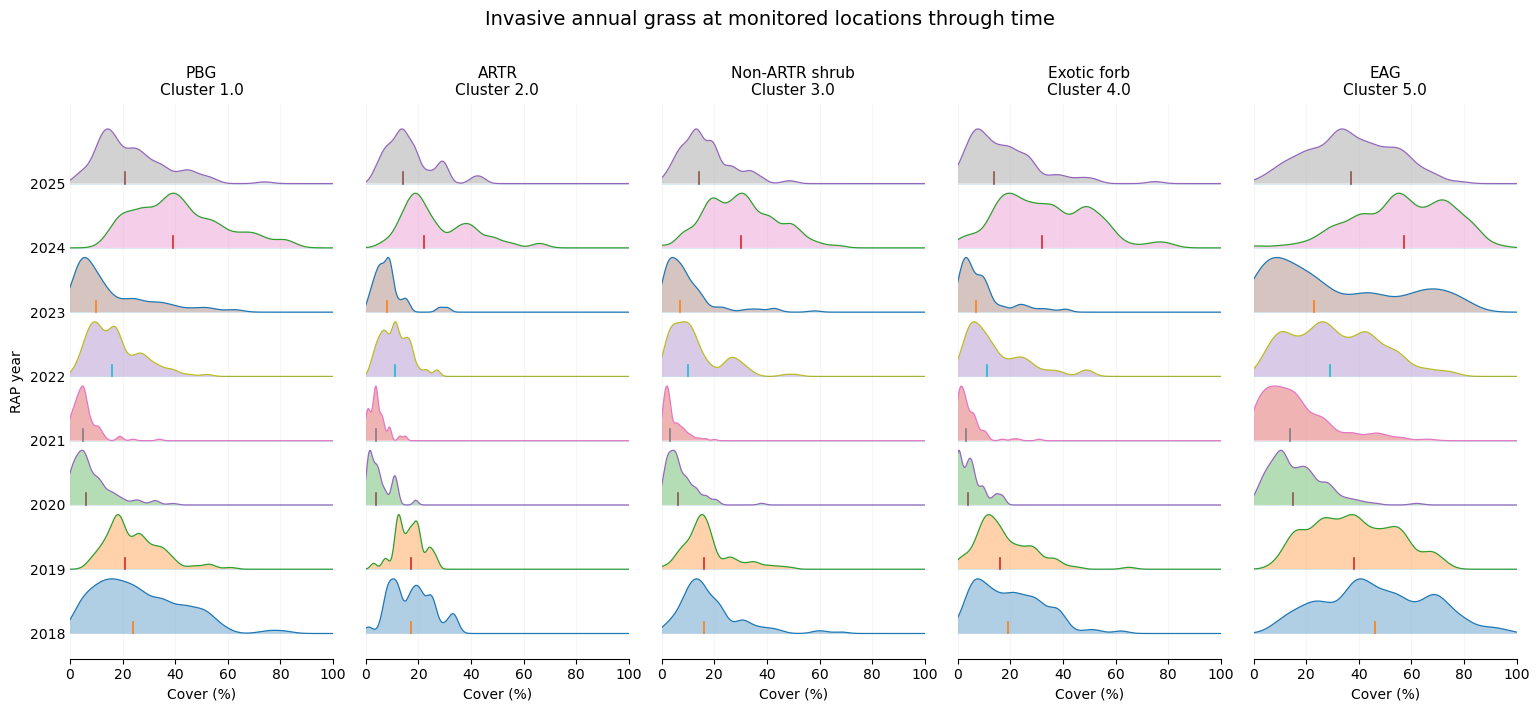

In [29]:
plot_rap_riparian(
    rap,
    "RAP_IAG_IAG"
)

In [30]:
# =============================================================================
# RAP DISTRIBUTION THROUGH TIME + CORRESPONDING FIELD FG SNAPSHOTS
# =============================================================================

def plot_rap_fan_with_field_snapshots(
    df,
    rap_col,
    field_col,
    field_label=None,
    rap_label=None,
    cluster_col="parent_cluster_k5",
    cluster_label_col="parent_cluster_label",
    rap_year_col="RAP_Year",
    field_year_col="year",
    ylim=None,
):
    """
    RAP cover distribution through time with observed field-functional-group
    snapshots in years when monitoring occurred.

    RAP:
        line        = median
        dark band   = 25th–75th percentile
        light band  = 10th–90th percentile

    Field:
        vertical segment = 25th–75th percentile
        filled point     = median

    Examples:
        RAP_IAG_IAG   <-> EAG_FG
        RAP_PFG       <-> PBG_FG
        RAP_SAGE_ARTE <-> ARTR_FG
    """

    data = df[
        [
            RECORD_ID,
            cluster_col,
            cluster_label_col,
            rap_year_col,
            field_year_col,
            rap_col,
            field_col,
        ]
    ].copy()

    data[rap_col] = pd.to_numeric(
        data[rap_col],
        errors="coerce"
    )

    data[field_col] = pd.to_numeric(
        data[field_col],
        errors="coerce"
    )

    data[rap_year_col] = pd.to_numeric(
        data[rap_year_col],
        errors="coerce"
    )

    data[field_year_col] = pd.to_numeric(
        data[field_year_col],
        errors="coerce"
    )


    # =========================================================================
    # RAP ANNUAL DISTRIBUTIONS
    # =========================================================================

    rap_summary = (
        data
        .dropna(
            subset=[
                cluster_col,
                rap_year_col,
                rap_col,
            ]
        )
        .groupby(
            [
                cluster_col,
                cluster_label_col,
                rap_year_col,
            ]
        )[rap_col]
        .agg(
            n="count",
            q10=lambda x: x.quantile(0.10),
            q25=lambda x: x.quantile(0.25),
            median="median",
            q75=lambda x: x.quantile(0.75),
            q90=lambda x: x.quantile(0.90),
        )
        .reset_index()
    )


    # =========================================================================
    # FIELD OBSERVATIONS
    #
    # Each PlotYearID is repeated once for every RAP year in `rap`.
    # Collapse to one row per actual monitored record before calculating field
    # distributions.
    # =========================================================================

    field_records = (
        data[
            [
                RECORD_ID,
                cluster_col,
                cluster_label_col,
                field_year_col,
                field_col,
            ]
        ]
        .drop_duplicates(subset=RECORD_ID)
        .dropna(
            subset=[
                cluster_col,
                field_year_col,
                field_col,
            ]
        )
    )

    field_summary = (
        field_records
        .groupby(
            [
                cluster_col,
                cluster_label_col,
                field_year_col,
            ]
        )[field_col]
        .agg(
            n="count",
            q25=lambda x: x.quantile(0.25),
            median="median",
            q75=lambda x: x.quantile(0.75),
        )
        .reset_index()
    )


    # =========================================================================
    # FIGURE
    # =========================================================================

    clusters = sorted(
        rap_summary[cluster_col]
        .dropna()
        .unique()
    )

    rap_years = sorted(
        rap_summary[rap_year_col]
        .dropna()
        .unique()
    )

    fig, axes = plt.subplots(
        1,
        len(clusters),
        figsize=(3.4 * len(clusters), 5.8),
        sharex=True,
        sharey=True,
    )

    if len(clusters) == 1:
        axes = [axes]


    for ax, cluster in zip(axes, clusters):

        r = (
            rap_summary.loc[
                rap_summary[cluster_col].eq(cluster)
            ]
            .sort_values(rap_year_col)
        )

        f = (
            field_summary.loc[
                field_summary[cluster_col].eq(cluster)
            ]
            .sort_values(field_year_col)
        )


        # ---------------------------------------------------------------------
        # RAP distribution
        # ---------------------------------------------------------------------

        x = r[rap_year_col].astype(float).to_numpy()

        ax.fill_between(
            x,
            r["q10"].astype(float),
            r["q90"].astype(float),
            alpha=0.10,
            linewidth=0,
            label="RAP 10–90%"
        )

        ax.fill_between(
            x,
            r["q25"].astype(float),
            r["q75"].astype(float),
            alpha=0.25,
            linewidth=0,
            label="RAP IQR"
        )

        ax.plot(
            x,
            r["median"].astype(float),
            marker="o",
            markersize=4,
            linewidth=1.5,
            label="RAP median"
        )


        # ---------------------------------------------------------------------
        # Observed field FG snapshots
        # ---------------------------------------------------------------------

        for j, (_, row) in enumerate(f.iterrows()):

            yr = float(row[field_year_col])

            # Field IQR
            ax.vlines(
                yr,
                row["q25"],
                row["q75"],
                color="black",
                linewidth=4,
                zorder=6,
                label="Field IQR" if j == 0 else None
            )

            # Field median
            ax.scatter(
                yr,
                row["median"],
                color="black",
                s=45,
                zorder=7,
                label="Field median" if j == 0 else None
            )


        # ---------------------------------------------------------------------
        # Facet label
        # ---------------------------------------------------------------------

        labels = (
            r[cluster_label_col]
            .dropna()
            .unique()
        )

        cluster_name = (
            str(labels[0])
            if len(labels)
            else f"Cluster {cluster}"
        )

        ax.set_title(
            f"{cluster_name}\nCluster {int(cluster)}"
        )

        ax.set_xlabel("Year")

        ax.set_xticks(rap_years)
        ax.tick_params(
            axis="x",
            rotation=45
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.grid(
            axis="y",
            alpha=0.12
        )

        if ylim is not None:
            ax.set_ylim(ylim)


    axes[0].set_ylabel("Cover (%)")


    # =========================================================================
    # LABELS
    # =========================================================================

    if field_label is None:
        field_label = field_col

    if rap_label is None:
        rap_label = RAP_LABELS.get(
            rap_col,
            rap_col
        )

    fig.suptitle(
        f"{field_label}: field observations and RAP cover through time",
        fontsize=14,
        y=1.02
    )


    # Shared legend; collect from one facet.
    handles, labels = axes[0].get_legend_handles_labels()

    unique = {}
    for handle, label in zip(handles, labels):
        if label not in unique:
            unique[label] = handle

    fig.legend(
        unique.values(),
        unique.keys(),
        loc="upper center",
        bbox_to_anchor=(0.5, 0.975),
        ncol=4,
        frameon=False,
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.91]
    )

    plt.show()

    return rap_summary, field_summary

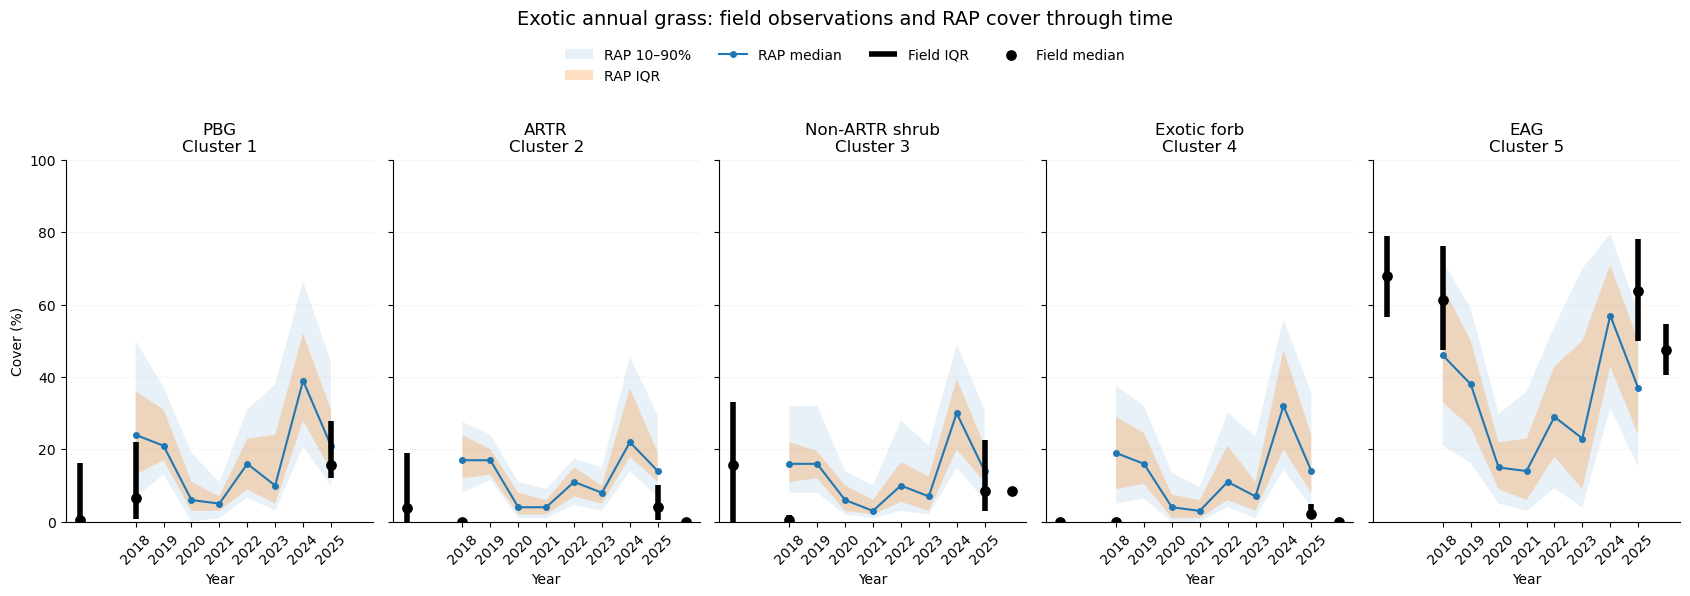

In [31]:
iag_rap, iag_field = plot_rap_fan_with_field_snapshots(
    rap,
    rap_col="RAP_IAG_IAG",
    field_col="EAG_FG",
    field_label="Exotic annual grass",
    rap_label="RAP invasive annual grass",
    ylim=(0, 100),
)

In [32]:
# =============================================================================
# TEMPORAL DISTRIBUTION INTERVALS:
# RAP THROUGH TIME + MATCHED FIELD FG SNAPSHOTS
# =============================================================================

def plot_rap_field_intervals(
    df,
    rap_col,
    field_col,
    field_label=None,
    cluster_col="parent_cluster_k5",
    cluster_label_col="parent_cluster_label",
    rap_year_col="RAP_Year",
    field_year_col="year",
    years=range(2018, 2026),
    ylim=(0, 100),
    field_offset=0.13,
):
    """
    Temporal distribution plot.

    RAP each year:
        thin vertical line  = 10–90%
        thick vertical line = IQR
        point               = median

    Field monitored years:
        black thick line    = IQR
        black point         = median

    Field observations outside the RAP period are excluded.
    """

    years = list(years)

    data = df[
        [
            RECORD_ID,
            cluster_col,
            cluster_label_col,
            rap_year_col,
            field_year_col,
            rap_col,
            field_col,
        ]
    ].copy()

    # -------------------------------------------------------------------------
    # Numeric coercion + explicit temporal restriction
    # -------------------------------------------------------------------------

    for col in [
        rap_col,
        field_col,
        rap_year_col,
        field_year_col,
    ]:
        data[col] = pd.to_numeric(
            data[col],
            errors="coerce"
        )

    data = data.loc[
        data[rap_year_col].isin(years)
    ].copy()


    # =========================================================================
    # RAP DISTRIBUTION BY CLUSTER × RAP YEAR
    # =========================================================================

    rap_summary = (
        data
        .dropna(
            subset=[
                cluster_col,
                rap_year_col,
                rap_col,
            ]
        )
        .groupby(
            [
                cluster_col,
                cluster_label_col,
                rap_year_col,
            ]
        )[rap_col]
        .agg(
            n="count",
            q10=lambda x: x.quantile(0.10),
            q25=lambda x: x.quantile(0.25),
            median="median",
            q75=lambda x: x.quantile(0.75),
            q90=lambda x: x.quantile(0.90),
        )
        .reset_index()
    )


    # =========================================================================
    # FIELD DISTRIBUTION
    #
    # One row per actual monitored PlotYearID.
    # Explicitly retain only monitoring years within RAP coverage.
    # =========================================================================

    field_records = (
        data[
            [
                RECORD_ID,
                cluster_col,
                cluster_label_col,
                field_year_col,
                field_col,
            ]
        ]
        .drop_duplicates(subset=RECORD_ID)
        .dropna(
            subset=[
                cluster_col,
                field_year_col,
                field_col,
            ]
        )
    )

    field_records = field_records.loc[
        field_records[field_year_col].isin(years)
    ].copy()


    field_summary = (
        field_records
        .groupby(
            [
                cluster_col,
                cluster_label_col,
                field_year_col,
            ]
        )[field_col]
        .agg(
            n="count",
            q25=lambda x: x.quantile(0.25),
            median="median",
            q75=lambda x: x.quantile(0.75),
        )
        .reset_index()
    )


    # =========================================================================
    # FACETS
    # =========================================================================

    clusters = sorted(
        rap_summary[cluster_col]
        .dropna()
        .unique()
    )

    fig, axes = plt.subplots(
        1,
        len(clusters),
        figsize=(3.2 * len(clusters), 5.5),
        sharex=True,
        sharey=True,
    )

    if len(clusters) == 1:
        axes = [axes]


    for ax, cluster in zip(
        axes,
        clusters
    ):

        r = (
            rap_summary.loc[
                rap_summary[cluster_col].eq(cluster)
            ]
            .sort_values(rap_year_col)
        )

        f = (
            field_summary.loc[
                field_summary[cluster_col].eq(cluster)
            ]
            .sort_values(field_year_col)
        )


        # ---------------------------------------------------------------------
        # RAP annual intervals
        # ---------------------------------------------------------------------

        for j, (_, row) in enumerate(r.iterrows()):

            yr = float(row[rap_year_col])

            # 10–90%
            ax.vlines(
                yr,
                row["q10"],
                row["q90"],
                linewidth=1,
                alpha=0.35,
                zorder=2,
            )

            # IQR
            ax.vlines(
                yr,
                row["q25"],
                row["q75"],
                linewidth=4,
                alpha=0.65,
                zorder=3,
            )

            # median
            ax.scatter(
                yr,
                row["median"],
                s=28,
                zorder=4,
                label="RAP median + intervals"
                if j == 0
                else None,
            )


        # Connect RAP medians only.
        ax.plot(
            r[rap_year_col],
            r["median"],
            linewidth=1,
            alpha=0.55,
            zorder=1,
        )


        # ---------------------------------------------------------------------
        # Field snapshots
        #
        # Slight horizontal offset prevents overlap with RAP interval.
        # ---------------------------------------------------------------------

        for j, (_, row) in enumerate(f.iterrows()):

            yr = float(row[field_year_col]) + field_offset

            ax.vlines(
                yr,
                row["q25"],
                row["q75"],
                color="black",
                linewidth=5,
                zorder=6,
                label="Field IQR"
                if j == 0
                else None,
            )

            ax.scatter(
                yr,
                row["median"],
                color="black",
                s=42,
                zorder=7,
                label="Field median"
                if j == 0
                else None,
            )


        # ---------------------------------------------------------------------
        # Cluster labels
        # ---------------------------------------------------------------------

        labels = (
            r[cluster_label_col]
            .dropna()
            .unique()
        )

        cluster_name = (
            str(labels[0])
            if len(labels)
            else f"Cluster {cluster}"
        )

        ax.set_title(
            f"{cluster_name}\nCluster {int(cluster)}"
        )

        ax.set_xlim(
            min(years) - 0.45,
            max(years) + 0.45
        )

        ax.set_xticks(years)

        ax.tick_params(
            axis="x",
            rotation=45
        )

        ax.set_xlabel("Year")

        ax.set_ylim(ylim)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.grid(
            axis="y",
            alpha=0.12
        )


    axes[0].set_ylabel("Cover (%)")


    if field_label is None:
        field_label = field_col


    fig.suptitle(
        f"{field_label}: RAP temporal distributions and field observations",
        fontsize=14,
        y=1.02,
    )


    # Shared legend
    handles, labels = axes[0].get_legend_handles_labels()

    unique = {}
    for handle, label in zip(handles, labels):
        unique.setdefault(label, handle)

    fig.legend(
        unique.values(),
        unique.keys(),
        loc="upper center",
        bbox_to_anchor=(0.5, 0.965),
        ncol=3,
        frameon=False,
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.91]
    )

    plt.show()

    return rap_summary, field_summary

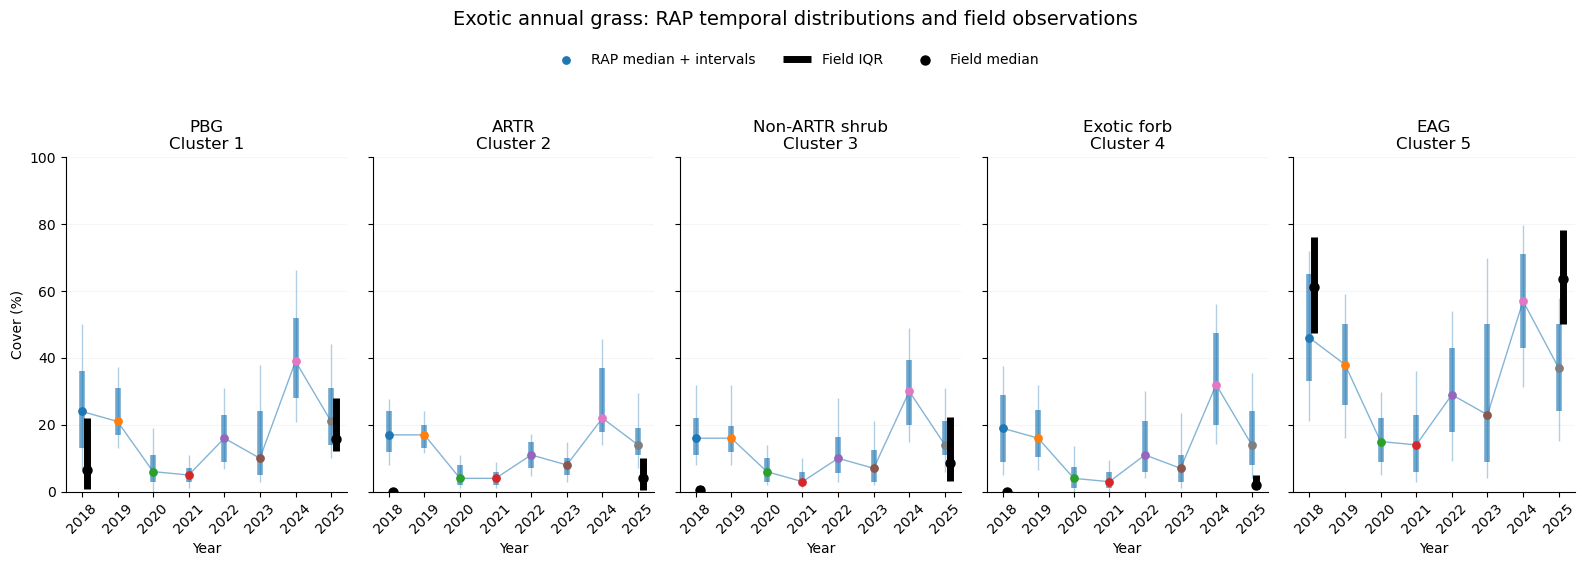

(    parent_cluster_k5 parent_cluster_label  RAP_Year    n   q10   q25  median   q75   q90
 0                 1.0                  PBG      2018  109   6.8  13.0    24.0  36.0  50.0
 1                 1.0                  PBG      2019  109  13.0  17.0    21.0  31.0  37.2
 2                 1.0                  PBG      2020  109   0.0   3.0     6.0  11.0  19.0
 3                 1.0                  PBG      2021  109   1.0   3.0     5.0   7.0  11.0
 4                 1.0                  PBG      2022  109   6.8   9.0    16.0  23.0  31.0
 5                 1.0                  PBG      2023  109   3.0   5.0    10.0  24.0  38.0
 6                 1.0                  PBG      2024  109  20.8  28.0    39.0  52.0  66.4
 7                 1.0                  PBG      2025  109  10.0  14.0    21.0  31.0  44.2
 8                 2.0                 ARTR      2018   37   8.0  12.0    17.0  24.0  27.6
 9                 2.0                 ARTR      2019   37  11.6  13.0    17.0  20.0  24.0

In [ ]:
plot_rap_field_intervals(
    rap,
    rap_col="RAP_IAG_IAG",
    field_col="EAG_FG",
    field_label="Exotic annual grass",
    ylim=(0, 100),
)

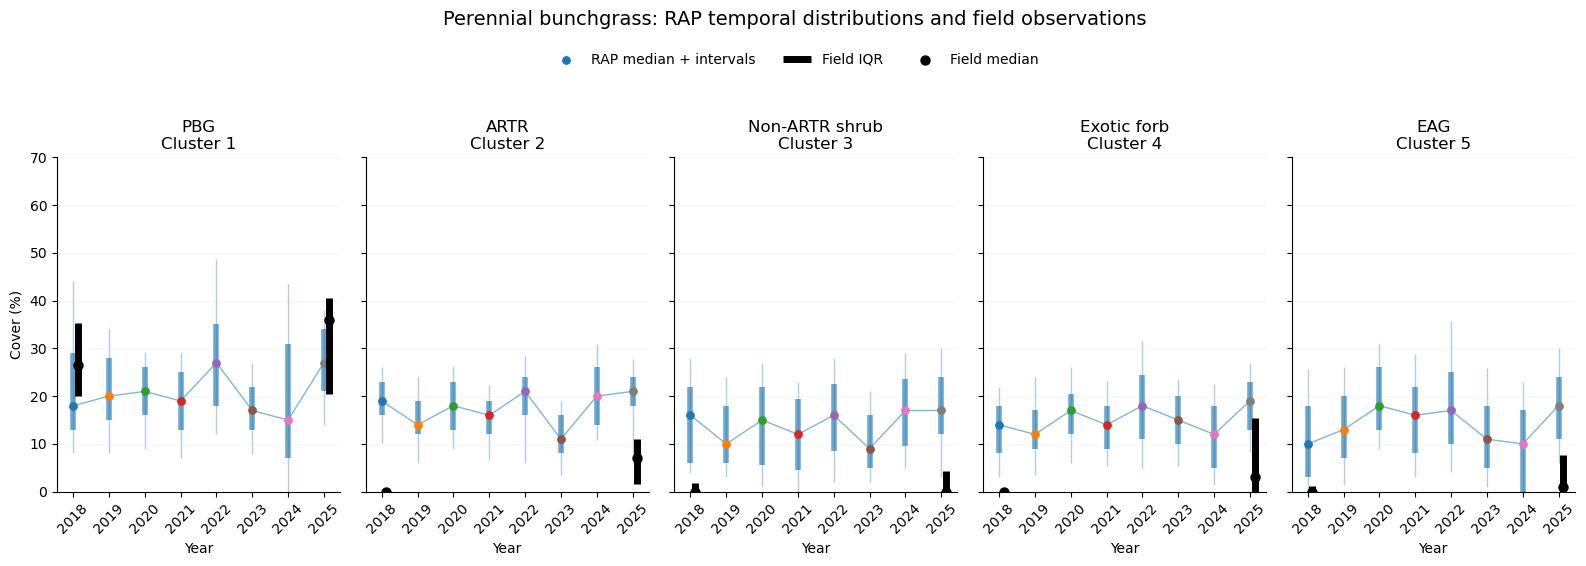

(    parent_cluster_k5 parent_cluster_label  RAP_Year    n   q10   q25  median   q75   q90
 0                 1.0                  PBG      2018  109   8.0  13.0    18.0  29.0  44.0
 1                 1.0                  PBG      2019  109   8.0  15.0    20.0  28.0  34.2
 2                 1.0                  PBG      2020  109   9.0  16.0    21.0  26.0  29.2
 3                 1.0                  PBG      2021  109   7.0  13.0    19.0  25.0  29.0
 4                 1.0                  PBG      2022  109  12.0  18.0    27.0  35.0  48.6
 5                 1.0                  PBG      2023  109   7.8  13.0    17.0  22.0  27.0
 6                 1.0                  PBG      2024  109   0.0   7.0    15.0  31.0  43.4
 7                 1.0                  PBG      2025  109  14.0  21.0    27.0  34.0  38.0
 8                 2.0                 ARTR      2018   37  10.2  16.0    19.0  23.0  26.0
 9                 2.0                 ARTR      2019   37   6.0  12.0    14.0  19.0  24.2

In [ ]:
plot_rap_field_intervals(
    rap,
    rap_col="RAP_PFG",
    field_col="PBG_FG",
    field_label="Perennial bunchgrass",
    ylim=(0, 70),
)

In [ ]:
# =============================================================================
# SPLIT VIOLINS:
# FIELD LEFT / RAP RIGHT AT MATCHED MONITORED YEARS
# FACETED BY PARENT CLUSTER
# =============================================================================

def plot_split_violin_field_vs_rap(
    df,
    rap_col,
    field_col,
    field_label=None,
    cluster_col="parent_cluster_k5",
    cluster_label_col="parent_cluster_label",
    rap_year_col="RAP_Year",
    field_year_col="year",
    years=(2018, 2025),
    ylim=(0, 100),
    width=0.34,
    bw_method=0.25,
):
    """
    Split violin comparison at matched monitored years.

    Left half  = observed field FG distribution
    Right half = RAP distribution at the same PlotYearID records

    Only records where:
        RAP_Year == field monitoring year

    are used.

    2016 and 2026 are excluded by `years`.
    """

    years = list(years)

    # -------------------------------------------------------------------------
    # Matched records only
    # -------------------------------------------------------------------------

    matched = df.loc[
        df[rap_year_col].eq(df[field_year_col])
        & df[field_year_col].isin(years),
        [
            RECORD_ID,
            cluster_col,
            cluster_label_col,
            rap_year_col,
            field_year_col,
            field_col,
            rap_col,
        ]
    ].copy()

    matched[field_col] = pd.to_numeric(
        matched[field_col],
        errors="coerce"
    )

    matched[rap_col] = pd.to_numeric(
        matched[rap_col],
        errors="coerce"
    )

    matched = matched.dropna(
        subset=[
            cluster_col,
            field_year_col,
            field_col,
            rap_col,
        ]
    )

    clusters = sorted(
        matched[cluster_col]
        .dropna()
        .unique()
    )

    # Common y-grid across entire figure.
    y = np.linspace(
        ylim[0],
        ylim[1],
        400
    )

    fig, axes = plt.subplots(
        1,
        len(clusters),
        figsize=(3.3 * len(clusters), 6),
        sharey=True
    )

    if len(clusters) == 1:
        axes = [axes]


    # =========================================================================
    # HELPER
    # =========================================================================

    def density(values):

        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]

        if len(values) < 3:
            return None

        if np.std(values) == 0:
            return None

        kde = stats.gaussian_kde(
            values,
            bw_method=bw_method
        )

        d = kde(y)

        if d.max() > 0:
            d = d / d.max()

        return d


    # =========================================================================
    # FACETS
    # =========================================================================

    for ax, cluster in zip(
        axes,
        clusters
    ):

        cdata = matched.loc[
            matched[cluster_col].eq(cluster)
        ]

        for i, yr in enumerate(years):

            d = cdata.loc[
                cdata[field_year_col].eq(yr)
            ]

            field_vals = d[field_col].dropna().to_numpy()
            rap_vals = d[rap_col].dropna().to_numpy()

            field_d = density(field_vals)
            rap_d = density(rap_vals)


            # -----------------------------------------------------------------
            # FIELD = LEFT HALF
            # -----------------------------------------------------------------

            if field_d is not None:

                ax.fill_betweenx(
                    y,
                    i - width * field_d,
                    i,
                    alpha=0.35
                )

                ax.plot(
                    i - width * field_d,
                    y,
                    linewidth=1
                )


            # -----------------------------------------------------------------
            # RAP = RIGHT HALF
            # -----------------------------------------------------------------

            if rap_d is not None:

                ax.fill_betweenx(
                    y,
                    i,
                    i + width * rap_d,
                    alpha=0.35
                )

                ax.plot(
                    i + width * rap_d,
                    y,
                    linewidth=1
                )


            # -----------------------------------------------------------------
            # MEDIANS
            # -----------------------------------------------------------------

            if len(field_vals):

                field_median = np.median(field_vals)

                ax.plot(
                    [i - 0.20, i - 0.04],
                    [field_median, field_median],
                    color="black",
                    linewidth=2
                )


            if len(rap_vals):

                rap_median = np.median(rap_vals)

                ax.plot(
                    [i + 0.04, i + 0.20],
                    [rap_median, rap_median],
                    linewidth=2
                )


            # Center divider
            ax.vlines(
                i,
                ylim[0],
                ylim[1],
                linewidth=0.5,
                alpha=0.15
            )


        # ---------------------------------------------------------------------
        # Cluster title
        # ---------------------------------------------------------------------

        labels = (
            cdata[cluster_label_col]
            .dropna()
            .unique()
        )

        label = (
            str(labels[0])
            if len(labels)
            else f"Cluster {cluster}"
        )

        ax.set_title(
            f"{label}\nCluster {int(cluster)}"
        )

        ax.set_xticks(
            range(len(years))
        )

        ax.set_xticklabels(
            [str(y) for y in years]
        )

        ax.set_xlabel("Monitoring year")

        ax.set_ylim(ylim)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.grid(
            axis="y",
            alpha=0.12
        )


    axes[0].set_ylabel(
        "Cover (%)"
    )


    if field_label is None:
        field_label = field_col


    fig.suptitle(
        f"{field_label}: field (left) vs RAP (right)",
        fontsize=14,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

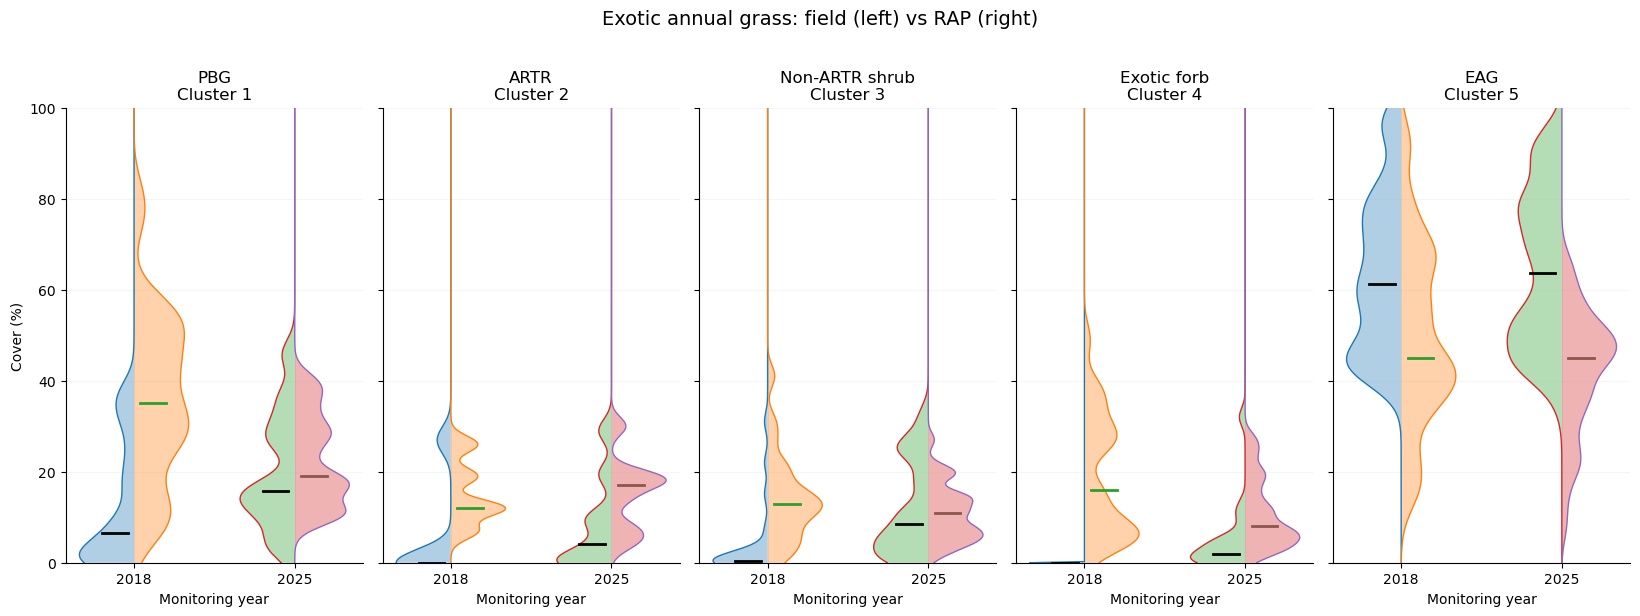

In [ ]:
plot_split_violin_field_vs_rap(
    rap,
    rap_col="RAP_IAG_IAG",
    field_col="EAG_FG",
    field_label="Exotic annual grass",
    years=(2018, 2025),
    ylim=(0, 100)
)

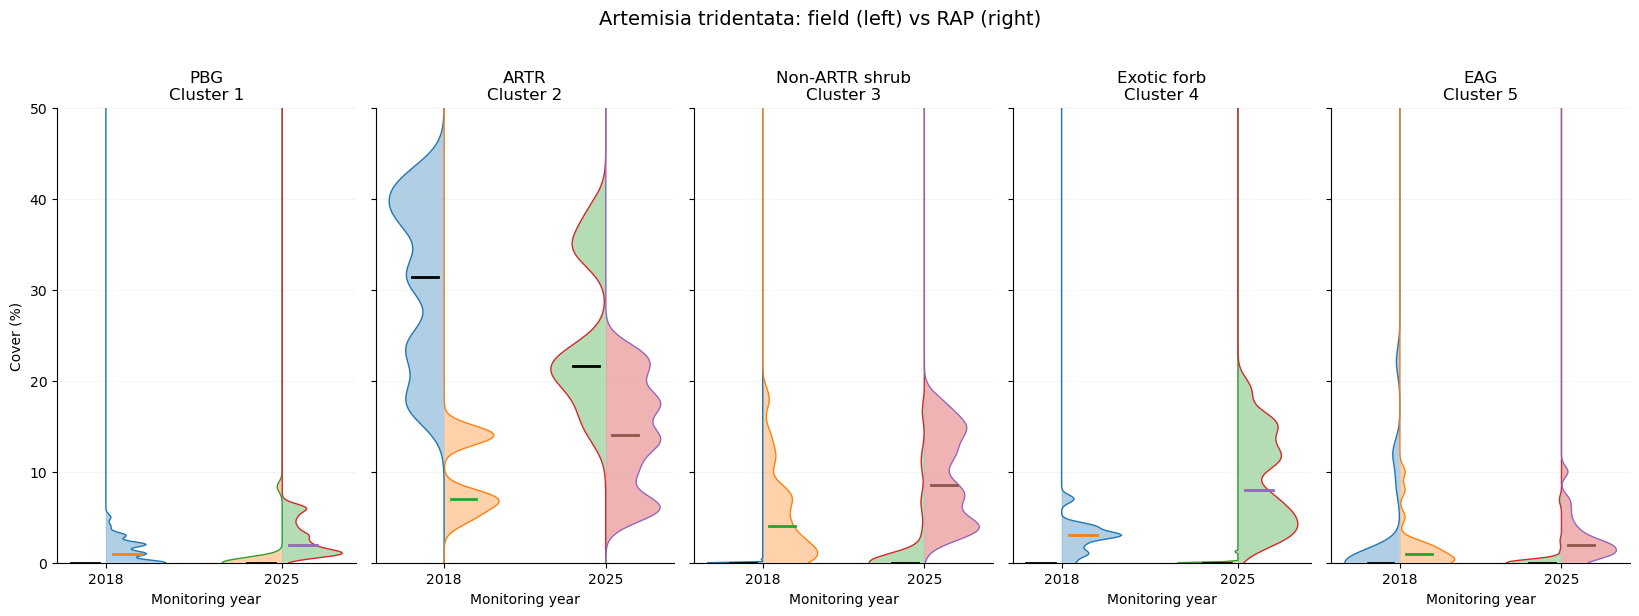

In [ ]:
plot_split_violin_field_vs_rap(
    rap,
    rap_col="RAP_SAGE_ARTE",
    field_col="ARTR_FG",
    field_label="Artemisia tridentata",
    years=(2018, 2025),
    ylim=(0, 50)
)

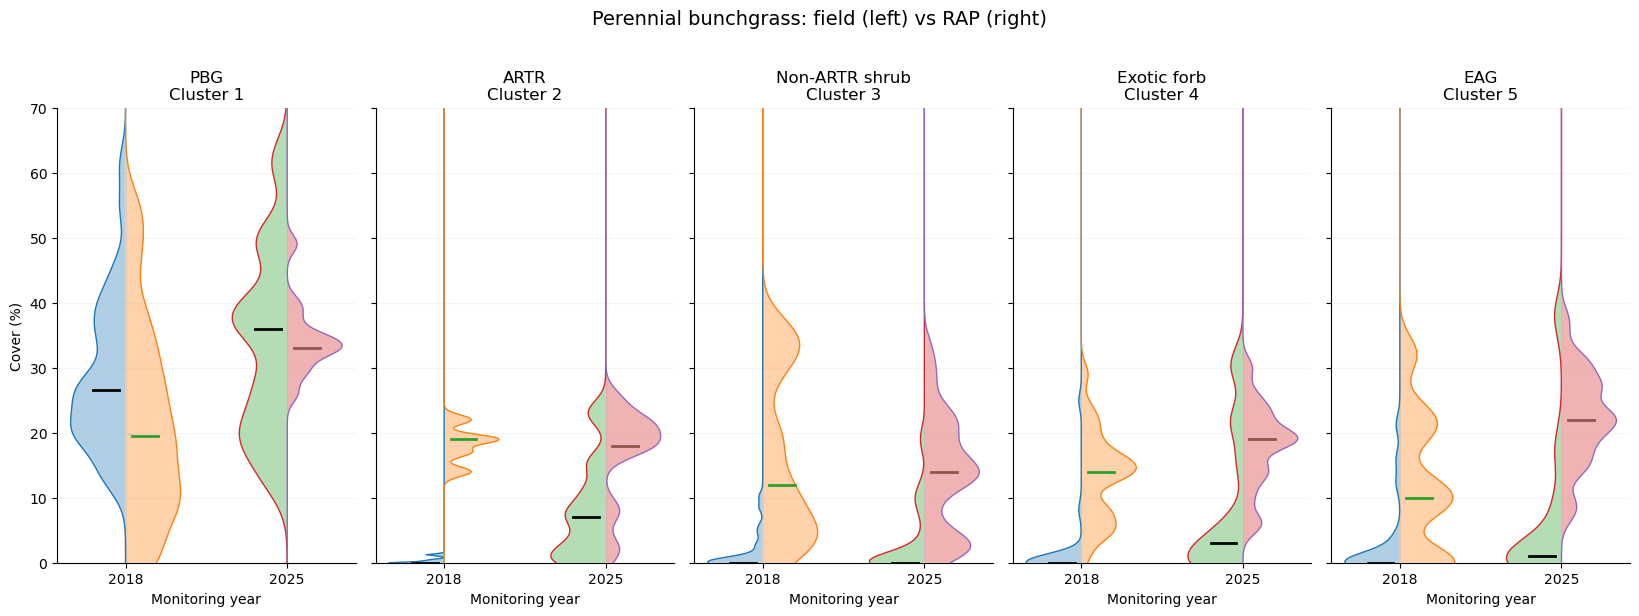

In [ ]:
plot_split_violin_field_vs_rap(
    rap,
    rap_col="RAP_PFG",
    field_col="PBG_FG",
    field_label="Perennial bunchgrass",
    years=(2018, 2025),
    ylim=(0, 70)
)

In [ ]:

# =============================================================================
# SPLIT VIOLIN FUNCTION
# FIELD LEFT / RAP RIGHT
# =============================================================================

def plot_split_violin_field_vs_rap(
    df,
    rap_col,
    field_col,
    field_label=None,
    rap_label=None,
    cluster_col=CLUSTER_COL,
    cluster_label_col=CLUSTER_LABEL_COL,
    rap_year_col=RAP_YEAR,
    field_year_col=FIELD_YEAR,
    years=MATCHED_YEARS,
    ylim=(0, 100),
    width=0.34,
    bw_method=0.25,
    zero_tol=1e-12,
):
    """
    Matched monitored-year comparison.

    Left half:
        observed field functional-group cover

    Right half:
        RAP cover at the same PlotYearID and same calendar year

    Violin density:
        positive observations only

    Median:
        calculated from the full distribution, including zeros

    Bottom annotations:
        n   = matched observations
        0%  = fraction of exact-zero observations

    Only years supplied in `years` are retained.
    """

    years = tuple(int(y) for y in years)

    # -------------------------------------------------------------------------
    # Same PlotYearID, same calendar year.
    # -------------------------------------------------------------------------

    matched = df.loc[
        df[rap_year_col].eq(df[field_year_col])
        & df[field_year_col].isin(years),
        [
            RECORD_ID,
            cluster_col,
            cluster_label_col,
            rap_year_col,
            field_year_col,
            field_col,
            rap_col,
        ]
    ].copy()

    matched[field_col] = pd.to_numeric(
        matched[field_col],
        errors="coerce"
    )

    matched[rap_col] = pd.to_numeric(
        matched[rap_col],
        errors="coerce"
    )

    matched[field_year_col] = pd.to_numeric(
        matched[field_year_col],
        errors="coerce"
    )

    matched = matched.dropna(
        subset=[
            RECORD_ID,
            cluster_col,
            field_year_col,
            field_col,
            rap_col,
        ]
    )

    # Defensive validation: one matched observation per PlotYearID.
    if matched[RECORD_ID].duplicated().any():
        dupes = matched.loc[
            matched[RECORD_ID].duplicated(keep=False),
            [RECORD_ID, field_year_col, rap_year_col]
        ]
        display(dupes.head(20))
        raise ValueError(
            "Matched split-violin data contain duplicate PlotYearID records."
        )

    clusters = sorted(
        matched[cluster_col]
        .dropna()
        .unique()
    )

    if not clusters:
        raise ValueError("No matched records remain for the requested years.")

    # Shared cover grid across all facets.
    y_grid = np.linspace(
        float(ylim[0]),
        float(ylim[1]),
        500
    )

    # Fixed source colors:
    # field = neutral gray; RAP = muted blue.
    field_fill = "#7F7F7F"
    field_line = "#222222"

    rap_fill = "#56B4E9"
    rap_line = "#0072B2"


    def positive_density(values):
        """
        KDE of positive observations only.

        Exact zeros are treated as a separate point mass and summarized
        explicitly below each violin.
        """

        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]

        positive = values[values > zero_tol]

        if len(positive) < 3:
            return None

        if np.nanstd(positive) <= 0:
            return None

        kde = stats.gaussian_kde(
            positive,
            bw_method=bw_method
        )

        d = kde(y_grid)

        if np.nanmax(d) <= 0:
            return None

        return d / np.nanmax(d)


    fig, axes = plt.subplots(
        1,
        len(clusters),
        figsize=(3.35 * len(clusters), 6.4),
        sharey=True
    )

    if len(clusters) == 1:
        axes = [axes]


    for ax, cluster in zip(axes, clusters):

        cdata = matched.loc[
            matched[cluster_col].eq(cluster)
        ].copy()

        for i, yr in enumerate(years):

            d = cdata.loc[
                cdata[field_year_col].eq(yr)
            ]

            field_vals = (
                d[field_col]
                .dropna()
                .to_numpy(dtype=float)
            )

            rap_vals = (
                d[rap_col]
                .dropna()
                .to_numpy(dtype=float)
            )

            if len(field_vals) == 0 or len(rap_vals) == 0:
                continue

            field_density = positive_density(field_vals)
            rap_density = positive_density(rap_vals)


            # -----------------------------------------------------------------
            # FIELD — LEFT HALF
            # -----------------------------------------------------------------

            if field_density is not None:

                ax.fill_betweenx(
                    y_grid,
                    i - width * field_density,
                    i,
                    facecolor=field_fill,
                    alpha=0.45,
                    linewidth=0,
                    zorder=2
                )

                ax.plot(
                    i - width * field_density,
                    y_grid,
                    color=field_line,
                    linewidth=1.0,
                    zorder=3
                )


            # -----------------------------------------------------------------
            # RAP — RIGHT HALF
            # -----------------------------------------------------------------

            if rap_density is not None:

                ax.fill_betweenx(
                    y_grid,
                    i,
                    i + width * rap_density,
                    facecolor=rap_fill,
                    alpha=0.45,
                    linewidth=0,
                    zorder=2
                )

                ax.plot(
                    i + width * rap_density,
                    y_grid,
                    color=rap_line,
                    linewidth=1.0,
                    zorder=3
                )


            # -----------------------------------------------------------------
            # FULL-DISTRIBUTION MEDIANS
            # -----------------------------------------------------------------

            field_median = np.nanmedian(field_vals)
            rap_median = np.nanmedian(rap_vals)

            ax.plot(
                [i - 0.22, i - 0.05],
                [field_median, field_median],
                color=field_line,
                linewidth=2.2,
                zorder=5
            )

            ax.plot(
                [i + 0.05, i + 0.22],
                [rap_median, rap_median],
                color=rap_line,
                linewidth=2.2,
                zorder=5
            )


            # -----------------------------------------------------------------
            # EXPLICIT ZERO MASS + SAMPLE SIZE
            # -----------------------------------------------------------------

            n_field = len(field_vals)
            n_rap = len(rap_vals)

            p0_field = np.mean(
                np.isclose(field_vals, 0, atol=zero_tol)
            )

            p0_rap = np.mean(
                np.isclose(rap_vals, 0, atol=zero_tol)
            )

            # Matched records should normally give equal n, but report each
            # source separately so missingness is visible if it occurs.
            annotation_y = ylim[0] + 0.018 * (ylim[1] - ylim[0])

            ax.text(
                i - 0.06,
                annotation_y,
                f"F n={n_field}\n0={p0_field:.0%}",
                ha="right",
                va="bottom",
                fontsize=7.5,
                color=field_line
            )

            ax.text(
                i + 0.06,
                annotation_y,
                f"R n={n_rap}\n0={p0_rap:.0%}",
                ha="left",
                va="bottom",
                fontsize=7.5,
                color=rap_line
            )


            # Subtle split centerline.
            ax.vlines(
                i,
                ylim[0],
                ylim[1],
                color="#BDBDBD",
                linewidth=0.55,
                zorder=1
            )


        # ---------------------------------------------------------------------
        # Facet title
        # ---------------------------------------------------------------------

        labels = (
            cdata[cluster_label_col]
            .dropna()
            .unique()
        )

        cluster_name = (
            str(labels[0])
            if len(labels)
            else f"Cluster {cluster}"
        )

        ax.set_title(
            f"{cluster_name}\nCluster {int(cluster)}",
            fontsize=11
        )

        ax.set_xticks(
            range(len(years))
        )

        ax.set_xticklabels(
            [str(y) for y in years]
        )

        ax.set_xlabel(
            "Monitoring year"
        )

        ax.set_ylim(
            ylim
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.grid(
            axis="y",
            alpha=0.10
        )


    axes[0].set_ylabel(
        "Cover (%)"
    )

    if field_label is None:
        field_label = field_col

    if rap_label is None:
        rap_label = RAP_LABELS.get(
            rap_col,
            rap_col
        )

    fig.suptitle(
        f"{field_label}: matched field vs RAP distributions",
        fontsize=14,
        y=1.02
    )

    # Explicit source key rather than using year-dependent colors.
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D

    legend_handles = [
        Patch(
            facecolor=field_fill,
            edgecolor=field_line,
            alpha=0.45,
            label=f"Field: {field_label}"
        ),
        Patch(
            facecolor=rap_fill,
            edgecolor=rap_line,
            alpha=0.45,
            label=f"RAP: {rap_label}"
        ),
        Line2D(
            [0],
            [0],
            color=field_line,
            linewidth=2.2,
            label="Median"
        )
    ]

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.975),
        ncol=3,
        frameon=False
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.91]
    )

    plt.show()

    return matched


NameError: name 'CLUSTER_LABEL_COL' is not defined

In [33]:
# =============================================================================
# OBSERVATION-LEVEL FIELD vs RAP SCATTERPLOTS
# =============================================================================

def plot_field_vs_rap_scatter(
    df,
    field_col,
    rap_col,
    field_label=None,
    rap_label=None,
    years=(2018, 2025),
    cluster_col="parent_cluster_k5",
    cluster_label_col="parent_cluster_label",
    field_year_col=FIELD_YEAR,
    rap_year_col=RAP_YEAR,
    lim=(0, 100),
):
    """
    Observation-level comparison of field cover vs RAP cover.

    Uses only records where:
        RAP_Year == field monitoring year

    Panels:
        one per matched monitoring year

    Point color:
        K5 parent cluster

    Reference:
        dashed line = perfect 1:1 agreement
        solid line  = OLS calibration relationship

    Panel statistics:
        n
        mean bias (RAP - Field)
        MAE
        Spearman rho
        OLS slope
    """

    years = tuple(int(y) for y in years)

    # -------------------------------------------------------------------------
    # Matched observations only
    # -------------------------------------------------------------------------

    matched = df.loc[
        df[rap_year_col].eq(df[field_year_col])
        & df[field_year_col].isin(years),
        [
            RECORD_ID,
            field_year_col,
            rap_year_col,
            cluster_col,
            cluster_label_col,
            field_col,
            rap_col,
        ]
    ].copy()

    matched[field_col] = pd.to_numeric(
        matched[field_col],
        errors="coerce"
    )

    matched[rap_col] = pd.to_numeric(
        matched[rap_col],
        errors="coerce"
    )

    matched = matched.dropna(
        subset=[
            RECORD_ID,
            field_col,
            rap_col,
            cluster_col,
        ]
    )

    # One field record should occur once here.
    if matched[RECORD_ID].duplicated().any():
        raise ValueError(
            "Matched scatter data contain duplicate PlotYearID records."
        )

    # -------------------------------------------------------------------------
    # Labels
    # -------------------------------------------------------------------------

    if field_label is None:
        field_label = field_col

    if rap_label is None:
        rap_label = RAP_LABELS.get(
            rap_col,
            rap_col
        )

    clusters = sorted(
        matched[cluster_col]
        .dropna()
        .unique()
    )

    # Stable cluster colors within all panels.
    cmap = plt.get_cmap("tab10")

    cluster_colors = {
        cluster: cmap(i)
        for i, cluster in enumerate(clusters)
    }

    # -------------------------------------------------------------------------
    # Figure
    # -------------------------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        len(years),
        figsize=(6.2 * len(years), 5.8),
        sharex=True,
        sharey=True,
    )

    if len(years) == 1:
        axes = [axes]

    stats_rows = []

    for ax, year in zip(
        axes,
        years
    ):

        d = matched.loc[
            matched[field_year_col].eq(year)
        ].copy()

        # -------------------------------------------------------------
        # Individual observations
        # -------------------------------------------------------------

        for cluster in clusters:

            dc = d.loc[
                d[cluster_col].eq(cluster)
            ]

            if dc.empty:
                continue

            labels = (
                dc[cluster_label_col]
                .dropna()
                .unique()
            )

            cluster_name = (
                str(labels[0])
                if len(labels)
                else f"Cluster {cluster}"
            )

            ax.scatter(
                dc[field_col],
                dc[rap_col],
                s=35,
                alpha=0.65,
                color=cluster_colors[cluster],
                edgecolors="none",
                label=f"{int(cluster)} — {cluster_name}",
            )

        # -------------------------------------------------------------
        # 1:1 agreement
        # -------------------------------------------------------------

        ax.plot(
            lim,
            lim,
            linestyle="--",
            linewidth=1,
            color="black",
            alpha=0.55,
            label="1:1",
        )

        # -------------------------------------------------------------
        # Calibration regression
        #
        # RAP = intercept + slope * Field
        # -------------------------------------------------------------

        x = d[field_col].to_numpy(dtype=float)
        y = d[rap_col].to_numpy(dtype=float)

        if len(d) >= 3 and np.nanstd(x) > 0:

            slope, intercept = np.polyfit(
                x,
                y,
                1
            )

            xline = np.array(lim)

            yline = (
                intercept
                + slope * xline
            )

            ax.plot(
                xline,
                yline,
                linewidth=1.6,
                alpha=0.85,
            )

        else:
            slope = np.nan
            intercept = np.nan

        # -------------------------------------------------------------
        # Diagnostics
        # -------------------------------------------------------------

        error = y - x

        bias = np.mean(error)
        mae = np.mean(np.abs(error))
        rmse = np.sqrt(np.mean(error ** 2))

        if len(d) >= 3:
            rho, _ = stats.spearmanr(
                x,
                y
            )

            pearson_r, _ = stats.pearsonr(
                x,
                y
            )

        else:
            rho = np.nan
            pearson_r = np.nan

        stats_rows.append({
            "year": year,
            "field_variable": field_col,
            "rap_variable": rap_col,
            "n": len(d),
            "bias": bias,
            "MAE": mae,
            "RMSE": rmse,
            "Spearman_rho": rho,
            "Pearson_r": pearson_r,
            "slope": slope,
            "intercept": intercept,
        })

        # -------------------------------------------------------------
        # Panel annotation
        # -------------------------------------------------------------

        annotation = (
            f"n = {len(d)}\n"
            f"bias = {bias:+.1f}\n"
            f"MAE = {mae:.1f}\n"
            f"ρ = {rho:.2f}\n"
            f"slope = {slope:.2f}"
        )

        ax.text(
            0.04,
            0.96,
            annotation,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=9,
        )

        ax.set_title(
            str(year)
        )

        ax.set_xlim(lim)
        ax.set_ylim(lim)

        ax.set_aspect(
            "equal",
            adjustable="box"
        )

        ax.set_xlabel(
            f"Field {field_label} (%)"
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.grid(
            alpha=0.10
        )

    axes[0].set_ylabel(
        f"RAP {rap_label} (%)"
    )

    fig.suptitle(
        f"{field_label}: field observations vs RAP",
        fontsize=14,
        y=1.01,
    )

    # One common cluster legend.
    handles, labels = axes[-1].get_legend_handles_labels()

    unique = {}

    for handle, label in zip(
        handles,
        labels
    ):
        unique.setdefault(
            label,
            handle
        )

    fig.legend(
        unique.values(),
        unique.keys(),
        loc="upper center",
        bbox_to_anchor=(0.5, 0.94),
        ncol=3,
        frameon=False,
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.88]
    )

    plt.show()

    return (
        matched,
        pd.DataFrame(stats_rows)
    )

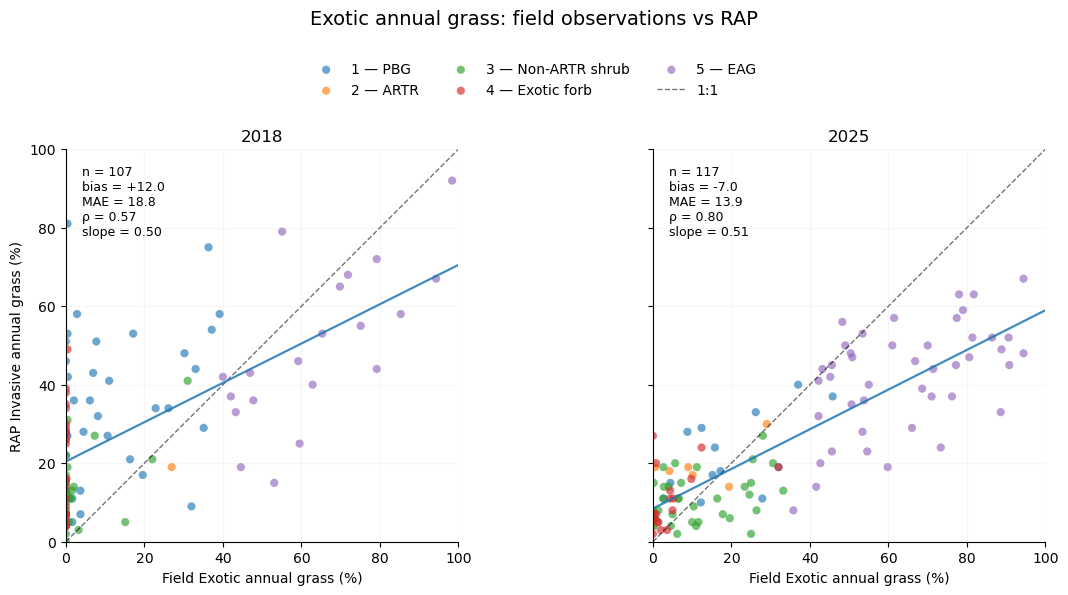

,year,field_variable,rap_variable,n,bias,MAE,RMSE,Spearman_rho,Pearson_r,slope,intercept
0,2018,EAG_FG,RAP_IAG_IAG,107,12.030343,18.768224,23.709665,0.572382,0.626573,0.500748,20.446493
1,2025,EAG_FG,RAP_IAG_IAG,117,-7.024691,13.880057,18.567919,0.803133,0.846038,0.505262,8.442786


In [34]:
eag_scatter, eag_stats = plot_field_vs_rap_scatter(
    rap,
    field_col="EAG_FG",
    rap_col="RAP_IAG_IAG",
    field_label="Exotic annual grass",
    rap_label="Invasive annual grass",
    lim=(0, 100),
)

display(eag_stats)

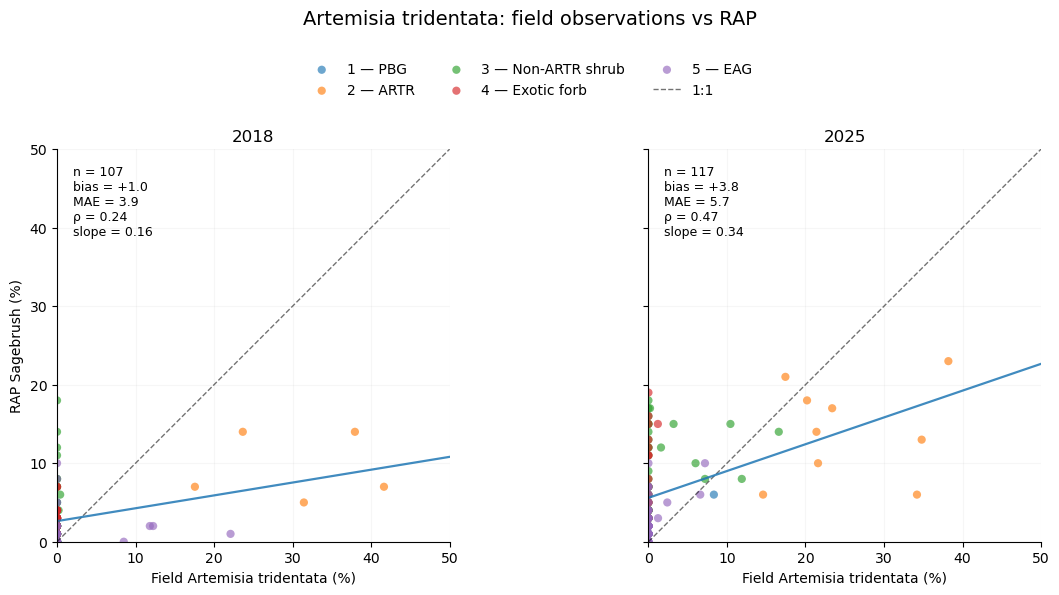

,year,field_variable,rap_variable,n,bias,MAE,RMSE,Spearman_rho,Pearson_r,slope,intercept
0,2018,ARTR_FG,RAP_SAGE_ARTE,107,1.004673,3.900000,6.910987,0.237956,0.333707,0.163666,2.626535
1,2025,ARTR_FG,RAP_SAGE_ARTE,117,3.846724,5.741121,7.918475,0.466638,0.446521,0.341264,5.591718


In [43]:
artr_scatter, artr_stats = plot_field_vs_rap_scatter(
    rap,
    field_col="ARTR_FG",
    rap_col="RAP_SAGE_ARTE",
    field_label="Artemisia tridentata",
    rap_label="Sagebrush",
    lim=(0, 50),
)

display(artr_stats)

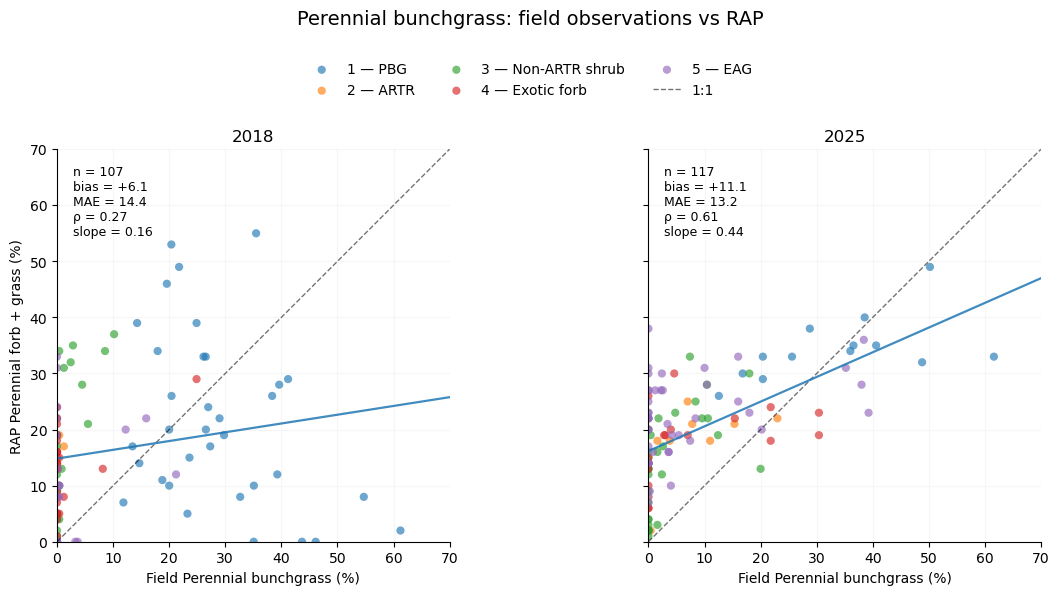

,year,field_variable,rap_variable,n,bias,MAE,RMSE,Spearman_rho,Pearson_r,slope,intercept
0,2018,PBG_FG,RAP_PFG,107,6.062944,14.435935,18.373316,0.267250,0.185584,0.156428,14.823994
1,2025,PBG_FG,RAP_PFG,117,11.146344,13.187464,15.396604,0.607088,0.611369,0.440247,16.173969


In [35]:
pbg_scatter, pbg_stats = plot_field_vs_rap_scatter(
    rap,
    field_col="PBG_FG",
    rap_col="RAP_PFG",
    field_label="Perennial bunchgrass",
    rap_label="Perennial forb + grass",
    lim=(0, 70),
)

display(pbg_stats)

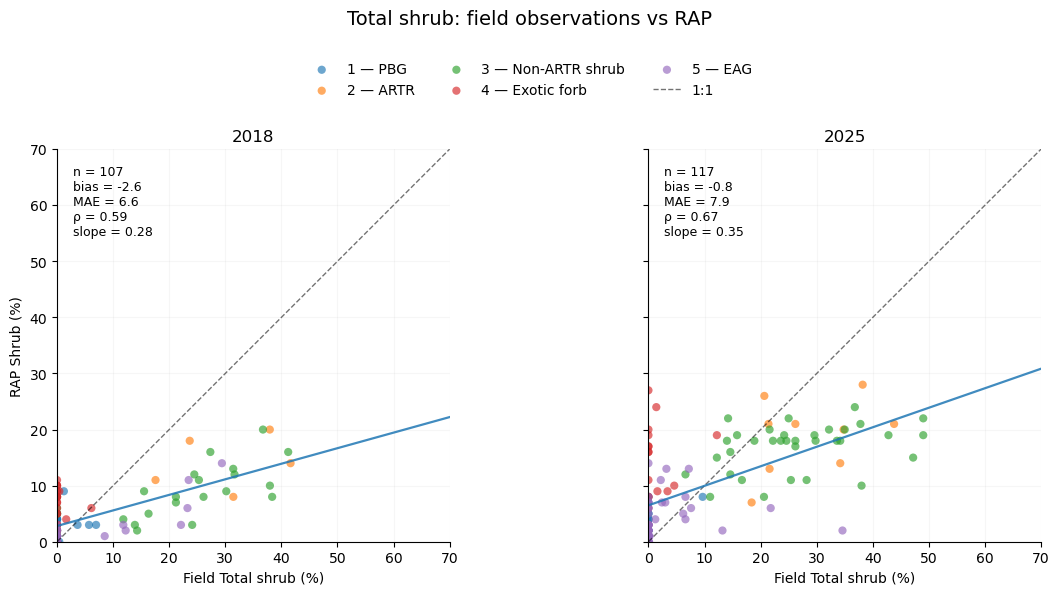

,year,field_variable,rap_variable,n,bias,MAE,RMSE,Spearman_rho,Pearson_r,slope,intercept
0,2018,SHRUB_TOTAL_FG,RAP_SHR,107,-2.581371,6.632586,9.852455,0.593716,0.700736,0.277346,2.809538
1,2025,SHRUB_TOTAL_FG,RAP_SHR,117,-0.808737,7.949098,11.032234,0.667547,0.647044,0.347951,6.489882


In [36]:
shrub_scatter, shrub_stats = plot_field_vs_rap_scatter(
    rap,
    field_col="SHRUB_TOTAL_FG",
    rap_col="RAP_SHR",
    field_label="Total shrub",
    rap_label="Shrub",
    lim=(0, 70),
)

display(shrub_stats)

In [41]:
bgr_scatter, bgr_stats = plot_field_vs_rap_scatter(
    rap,
    field_col="BARE",
    rap_col="RAP_BGR",
    field_label="Bare ground + biological soil crust",
    rap_label="Bare ground",
    lim=(0, 100),
)

display(bgr_stats)

KeyError: "['BARE'] not in index"

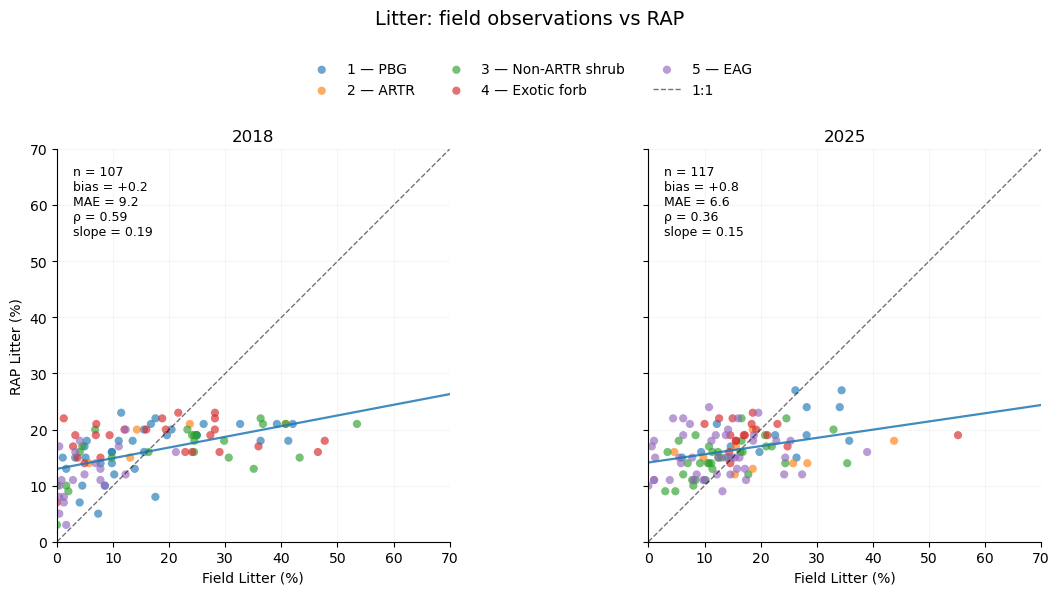

,year,field_variable,rap_variable,n,bias,MAE,RMSE,Spearman_rho,Pearson_r,slope,intercept
0,2018,LITTER_FG,RAP_LTR,107,0.216231,9.205452,11.436904,0.594171,0.536465,0.190286,12.996566
1,2025,LITTER_FG,RAP_LTR,117,0.840266,6.607407,8.887936,0.360374,0.350240,0.146375,14.123902


In [42]:
litter_scatter, litter_stats = plot_field_vs_rap_scatter(
    rap,
    field_col="LITTER_FG",
    rap_col="RAP_LTR",
    field_label="Litter",
    rap_label="Litter",
    lim=(0, 70),
)

display(litter_stats)